# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import pickle
import os
import glob

## df

In [2]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df_uniques = [val for val in df['position_state'].unique()]
df['position_state_id'] = df.groupby('position_state').transform('ngroup')
print(len(df_uniques))
df.head(2)

(13134, 11)
947


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,864,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,863,1.021119,968.0,1


In [3]:
df[['position_state_id', 'position_state']].nunique()

position_state_id    947
position_state       947
dtype: int64

## apd

In [4]:
ziped_apd = True

In [5]:
if ziped_apd:
    apd = pd.read_parquet('apd_ziped.gzip')
else:
    apd = pd.read_parquet('apd_full.gzip')

In [6]:
print(apd.shape)
apd_uniques = [val for val in apd['position_state'].unique()]
print(len(apd_uniques))
apd.head(2)

(1002001, 5)
1057


,X,Y,pos,position_state,position_state_id
0,0.000,0.0,"[0.0, 0.0]",COQVSOAUMTASMTUPCRFN,225
1,0.001,0.0,"[0.001, 0.0]",COQVSOAUMTASMTUPCRFN,225


## ps_to_psid

In [7]:
if 'position_state_id' not in apd.columns:
    with open('ps_to_psid.pkl', 'rb') as file:
        ps_to_psid = pickle.load(file)

In [8]:
if 'position_state_id' not in apd.columns:
    apd['position_state_id'] = [ps_to_psid[k] for k in apd['position_state']]

## cossim

In [9]:
coss = pd.read_csv("cosine_similarity_matrix_gpt.csv")
print(coss.shape)
coss.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.036386,-0.023867,-0.015813,-0.015845,0.032338,0.027366,-0.036902,0.032188,0.056944,...,-0.016691,0.001024,0.007142,0.041714,0.031872,0.036198,0.039436,-0.081653,-0.001333,0.0
1,0.036386,1.000000,0.053144,-0.039027,-0.007703,0.023032,0.016757,-0.004219,-0.030829,-0.033548,...,0.025244,-0.078716,-0.039884,0.013366,0.024962,-0.016389,0.001953,-0.010368,-0.036747,0.0
2,-0.023867,0.053144,1.000000,-0.017175,0.003883,-0.042288,-0.004441,0.020275,0.036950,-0.101246,...,0.074440,-0.042841,0.020596,0.047998,-0.020273,0.041833,0.023356,-0.069619,0.030495,0.0
3,-0.015813,-0.039027,-0.017175,1.000000,0.001555,0.082356,0.030432,0.074147,0.017862,0.005681,...,0.021251,0.022563,0.030433,0.006846,-0.049909,0.040710,0.009741,0.051818,-0.059704,0.0
4,-0.015845,-0.007703,0.003883,0.001555,1.000000,0.008367,0.005718,0.024092,-0.047963,-0.029800,...,-0.016851,-0.069240,0.013931,-0.017514,-0.039716,-0.050068,-0.041033,-0.017934,0.067465,0.0


## heads

In [10]:
head0 = pd.read_csv("head0_cosine_similarity_gpt.csv")
print(head0.shape)
head1 = pd.read_csv("head1_cosine_similarity_gpt.csv")
print(head1.shape)
head1.head()

(948, 948)
(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,-0.194990,0.082343,-0.001508,0.123069,-0.137875,-0.085304,-0.022181,-0.125097,0.149414,-0.016047,...,-0.023572,0.025183,-0.034323,0.010788,-0.109909,-0.059635,-0.076738,-0.103356,-0.062983,NaN
1,0.020695,0.071577,0.183210,-0.048534,0.041569,0.025589,-0.158280,-0.008303,0.008452,0.005471,...,-0.039575,-0.060028,0.069316,-0.044846,0.097880,-0.007060,-0.041993,-0.009750,-0.018702,NaN
2,-0.078615,0.097348,-0.109845,0.011410,-0.097538,-0.041064,-0.016618,0.018718,0.030465,0.010787,...,-0.017164,-0.043814,-0.035997,-0.073357,0.094039,-0.116253,-0.092846,-0.035257,0.232714,NaN
3,0.174415,-0.000321,-0.206112,-0.157259,0.088932,0.404964,-0.141399,-0.068914,-0.050388,0.027511,...,-0.063038,-0.116923,-0.056322,-0.063694,-0.038341,-0.135357,-0.011707,-0.172099,0.031503,NaN
4,-0.038438,-0.019378,0.204863,-0.163757,-0.075926,-0.488016,0.262906,0.050713,-0.008913,0.053400,...,-0.041102,0.030607,-0.063424,0.122481,0.028243,0.084022,0.030386,-0.008963,-0.020981,NaN


## heat att

In [11]:
head0_att = pd.read_csv("head0_attention_softmax_gpt.csv",)
head0_att.drop('947', axis=1, inplace=True)
head0_att.drop(947, inplace=True)
print(head0_att.shape)
head1_att = pd.read_csv("head1_attention_softmax_gpt.csv",)
head1_att.drop('947', axis=1, inplace=True)
head1_att.drop(947, inplace=True)
print(head1_att.shape)

head1_att.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,0.000076,0.001740,0.000676,0.003364,0.000105,2.387595e-04,0.000502,0.000171,0.004648,0.000567,...,0.000931,0.000512,0.000919,0.000457,0.000788,0.000163,0.000339,0.000300,0.000148,0.000291
1,0.000845,0.001497,0.007500,0.000358,0.001181,9.199752e-04,0.000069,0.000610,0.000745,0.000715,...,0.000831,0.000405,0.000338,0.001538,0.000386,0.002417,0.000615,0.000424,0.000578,0.000517
2,0.000205,0.001725,0.000112,0.000624,0.000127,3.075973e-04,0.000412,0.000667,0.000809,0.000613,...,0.000401,0.000422,0.000312,0.000335,0.000203,0.002002,0.000120,0.000181,0.000303,0.016485
3,0.003356,0.000414,0.000023,0.000048,0.001507,8.708251e-02,0.000048,0.000184,0.000210,0.000593,...,0.000202,0.000179,0.000101,0.000203,0.000181,0.000244,0.000075,0.000363,0.000027,0.000657
4,0.000281,0.000360,0.009995,0.000042,0.000141,4.559014e-07,0.033848,0.000879,0.000405,0.000969,...,0.000235,0.000255,0.000686,0.000194,0.002554,0.000703,0.001445,0.000671,0.000396,0.000332


## head attn w pos softmax

In [12]:
head0_att_pos_softmax = pd.read_csv(f"head0_softmax_pos0_to_pos1_gpt.csv", )
head0_att_pos_softmax.drop('947', axis=1, inplace=True)
head0_att_pos_softmax.drop(947, inplace=True)
print(head0_att_pos_softmax.shape)

head1_att_pos_softmax = pd.read_csv(f"head1_softmax_pos0_to_pos1_gpt.csv", )
head1_att_pos_softmax.drop('947', axis=1, inplace=True)
head1_att_pos_softmax.drop(947, inplace=True)
print(head1_att_pos_softmax.shape)

head1_att_pos_softmax.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,0.000311,0.001278,0.000224,0.001921,0.000176,4.730937e-04,0.000331,0.000099,0.001339,0.000850,...,0.000223,0.000145,0.000327,0.000281,0.000952,0.000020,0.000178,0.000635,0.000177,0.000071
1,0.003000,0.000957,0.002161,0.000178,0.001725,1.588446e-03,0.000040,0.000308,0.000187,0.000934,...,0.000174,0.000100,0.000105,0.000823,0.000406,0.000260,0.000282,0.000781,0.000603,0.000110
2,0.001211,0.001835,0.000054,0.000516,0.000309,8.832375e-04,0.000394,0.000561,0.000338,0.001332,...,0.000139,0.000173,0.000161,0.000298,0.000355,0.000358,0.000092,0.000553,0.000525,0.005844
3,0.009304,0.000207,0.000005,0.000019,0.001720,1.174420e-01,0.000022,0.000073,0.000041,0.000605,...,0.000033,0.000034,0.000025,0.000085,0.000149,0.000020,0.000027,0.000523,0.000022,0.000109
4,0.001175,0.000271,0.003389,0.000024,0.000243,9.262753e-07,0.022879,0.000523,0.000120,0.001488,...,0.000058,0.000074,0.000250,0.000122,0.003167,0.000089,0.000780,0.001456,0.000486,0.000083


## head attn w pos logit

In [13]:
head0_att_pos_logit = pd.read_csv(f"head0_logit_pos0_to_pos1_gpt.csv", )
head0_att_pos_logit.drop('947', axis=1, inplace=True)
head0_att_pos_logit.drop(947, inplace=True)
print(head0_att_pos_logit.shape)

head1_att_pos_logit = pd.read_csv(f"head1_logit_pos0_to_pos1_gpt.csv", )
head1_att_pos_logit.drop('947', axis=1, inplace=True)
head1_att_pos_logit.drop(947, inplace=True)
print(head1_att_pos_logit.shape)

head1_att_pos_logit.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,-0.336119,1.076552,-0.665926,1.484614,-0.905743,0.083086,-0.274269,-1.478038,1.123203,0.669298,...,-0.668422,-1.098108,-0.285605,-0.439057,0.782512,-3.071300,-0.892634,0.377671,-0.898053,-1.812018
1,1.887922,0.745761,1.560062,-0.936269,1.334769,1.252079,-2.439713,-0.386773,-0.887264,0.720724,...,-0.961879,-1.511921,-1.465774,0.594438,-0.111468,-0.557208,-0.476652,0.542660,0.282952,-1.415594
2,3.131210,3.546607,0.018758,2.278095,1.765653,2.815206,2.007580,2.361122,1.853497,3.226106,...,0.968832,1.186512,1.113163,1.728526,1.903492,1.913392,0.548483,2.347843,2.295541,4.704811
3,5.533283,1.726891,-1.947708,-0.668109,3.845239,8.068834,-0.527754,0.680928,0.112480,2.800115,...,-0.108851,-0.065707,-0.401946,0.835168,1.400899,-0.584662,-0.314967,2.654232,-0.497300,1.090617
4,0.347674,-1.119555,1.407172,-3.524926,-1.227364,-6.797802,3.316742,-0.461279,-1.936795,0.584108,...,-2.663954,-2.414767,-1.198150,-1.917236,1.339197,-2.231767,-0.061871,0.562180,-0.535538,-2.298518


## head attn w pos cossine

In [14]:
head0_att_pos_coss = pd.read_csv(f"head0_cosine_pos0_to_pos1_gpt.csv", )
head0_att_pos_coss.drop('947', axis=1, inplace=True)
head0_att_pos_coss.drop(947, inplace=True)
print(head0_att_pos_coss.shape)

head1_att_pos_coss = pd.read_csv(f"head1_cosine_pos0_to_pos1_gpt.csv", )
head1_att_pos_coss.drop('947', axis=1, inplace=True)
head1_att_pos_coss.drop(947, inplace=True)
print(head1_att_pos_coss.shape)

head1_att_pos_coss.head()

(947, 947)
(947, 947)


,0,1,2,3,4,5,6,7,8,9,...,937,938,939,940,941,942,943,944,945,946
0,-0.015189,0.044021,-0.029605,0.059489,-0.035187,0.003222,-0.010299,-0.061677,0.039885,0.027870,...,-0.027009,-0.041634,-0.012464,-0.022710,0.030736,-0.112737,-0.036303,0.015371,-0.034570,-0.062836
1,0.082825,0.029605,0.067331,-0.036421,0.050341,0.047141,-0.088938,-0.015669,-0.030587,0.029135,...,-0.037732,-0.055650,-0.062099,0.029850,-0.004250,-0.019856,-0.018820,0.021442,0.010574,-0.047656
2,0.149226,0.152942,0.000879,0.096268,0.072339,0.115142,0.079502,0.103907,0.069411,0.141671,...,0.041285,0.047442,0.051230,0.094291,0.078848,0.074069,0.023525,0.100775,0.093190,0.172059
3,0.228695,0.064583,-0.079194,-0.024485,0.136626,0.286203,-0.018125,0.025988,0.003653,0.106640,...,-0.004023,-0.002278,-0.016043,0.039510,0.050325,-0.019628,-0.011716,0.098801,-0.017508,0.034590
4,0.014906,-0.043433,0.059351,-0.134003,-0.045237,-0.250119,0.118160,-0.018262,-0.065249,0.023076,...,-0.102123,-0.086860,-0.049606,-0.094086,0.049904,-0.077721,-0.002387,0.021708,-0.019558,-0.075621


## distribs probs

In [29]:
distribs_probs = pd.read_csv('gpt_probs_distribs.csv',)
print(distribs_probs.shape)
distribs_probs.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.662680e-06,3.177991e-06,4.009456e-06,1.145890e-06,2.520847e-06,0.000004,5.748174e-06,8.418958e-06,1.464796e-07,0.000228
1,2.157076e-07,1.543836e-07,1.201682e-07,5.364881e-08,7.375746e-07,0.000002,4.088467e-07,4.277045e-07,1.134515e-08,0.000080


In [30]:
distribs_probs705 = pd.read_csv('gpt_probs_distribs_705.csv',)
print(distribs_probs.shape)
distribs_probs.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.662680e-06,3.177991e-06,4.009456e-06,1.145890e-06,2.520847e-06,0.000004,5.748174e-06,8.418958e-06,1.464796e-07,0.000228
1,2.157076e-07,1.543836e-07,1.201682e-07,5.364881e-08,7.375746e-07,0.000002,4.088467e-07,4.277045e-07,1.134515e-08,0.000080


## distrib logits

In [16]:
distribs_logits = pd.read_csv('gpt_logits_distribs.csv',)
print(distribs_logits.shape)
distribs_logits.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,-0.516477,0.209269,0.619511,0.223233,1.688363,0.889871,1.826185,2.989520,1.319123,2.607028
1,-3.348503,-2.815295,-2.888007,-2.838245,0.459379,0.303634,-0.817112,0.009711,-1.238973,1.564950


# An

## funcs

In [17]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = plt.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="upper right")

    # Não chama plt.show(); quem usa decide salvar/mostrar

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

def plot_position_states_emphasis_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # fundo (não destacados)
    s_outros: int = 10,
    s_prev: int = 26,              # anteriores (cinza escuro)
    s_penultimo: int = 28,         # penúltimo (preto)
    s_ultimo: int = 30,            # último (vermelho)
    annotate: bool = True,
    cor_prev: str = "#4a4a4a",     # cinza escuro
    cor_penultimo: str = "#000000",# preto
    cor_ultimo: str = "#d32f2f",   # vermelho
):
    """
    Plota conforme regra fixa de cores (sem colormap), **considerando a ÚLTIMA ocorrência
    de cada id** em `grupos_destacados`:

      - último  (id cuja ÚLTIMA ocorrência é a maior)     -> vermelho
      - penúltimo (2ª maior última ocorrência)            -> preto
      - anteriores (demais ids)                           -> cinza escuro
      - demais (não destacados)                           -> cinza claro
    """
    required = {"X", "Y", "position_state_id"}
    if not required.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # --- pega a ÚLTIMA ocorrência de cada id ---
    last_idx = {}
    for i, gid in enumerate(grupos_destacados):
        last_idx[gid] = i  # sobrescreve, guardando SEMPRE a última posição

    if len(last_idx) == 0:
        # nada a destacar: só fundo
        plt.figure(figsize=(12, 12))
        plt.scatter(apd["X"], apd["Y"], color=cor_outros, s=s_outros, zorder=1)
        _finalize_axes(title)
        return

    # ids ordenados pelo índice da última ocorrência (crescentemente “antigos” → “recentes”)
    ids_by_last = sorted(last_idx.keys(), key=lambda k: last_idx[k])
    n = len(ids_by_last)

    # define grupos por papel (anteriores / penúltimo / último)
    if n == 1:
        anteriores_ids = []
        penultimo_id = None
        ultimo_id = ids_by_last[-1]
    elif n == 2:
        anteriores_ids = []
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]
    else:
        anteriores_ids = ids_by_last[:-2]
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]

    plt.figure(figsize=(12, 12))

    # 1) fundo (não destacados)
    destaque_mask = apd["position_state_id"].isin(ids_by_last)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    # 2) anteriores (cinza escuro)
    for gid in anteriores_ids:
        grp = apd[apd["position_state_id"] == gid]
        if not grp.empty:
            plt.scatter(grp["X"], grp["Y"], color=cor_prev, s=s_prev, zorder=2)

    # 3) penúltimo (preto)
    if penultimo_id is not None:
        grp_pen = apd[apd["position_state_id"] == penultimo_id]
        if not grp_pen.empty:
            plt.scatter(grp_pen["X"], grp_pen["Y"], color=cor_penultimo, s=s_penultimo, zorder=3)

    # 4) último (vermelho)
    grp_last = apd[apd["position_state_id"] == ultimo_id]
    if not grp_last.empty:
        plt.scatter(grp_last["X"], grp_last["Y"], color=cor_ultimo, s=s_ultimo, zorder=4, label="Último")

    # 5) anotações (opcional) – sobre ids distintos (pela última ocorrência)
    if annotate:
        medias = apd[apd["position_state_id"].isin(ids_by_last)] \
                    .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            txt = plt.annotate(
                str(row["position_state_id"]),
                (row["X"], row["Y"]),
                fontsize=8, ha="center", va="center",
                color="black", fontweight="bold", zorder=5
            )
            txt.set_path_effects([pe.withStroke(linewidth=2.5, foreground="white")])

    _finalize_axes(title if title else "Grupos destacados (última ocorrência: cinza/preto/vermelho)")


def _finalize_axes(title):
    """Acabamento padrão do gráfico."""
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        seen, uniq_h, uniq_l = set(), [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_h.append(h); uniq_l.append(l); seen.add(l)
        plt.legend(uniq_h, uniq_l, loc="upper right")


In [19]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10,)

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        # cbar = plt.colorbar(scatter)
        # cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.show()

In [16]:
# plot_position_states(apd, [0, 220, 221, 950])

# Embedding

In [12]:
def plot_similarity_to_group_from_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()


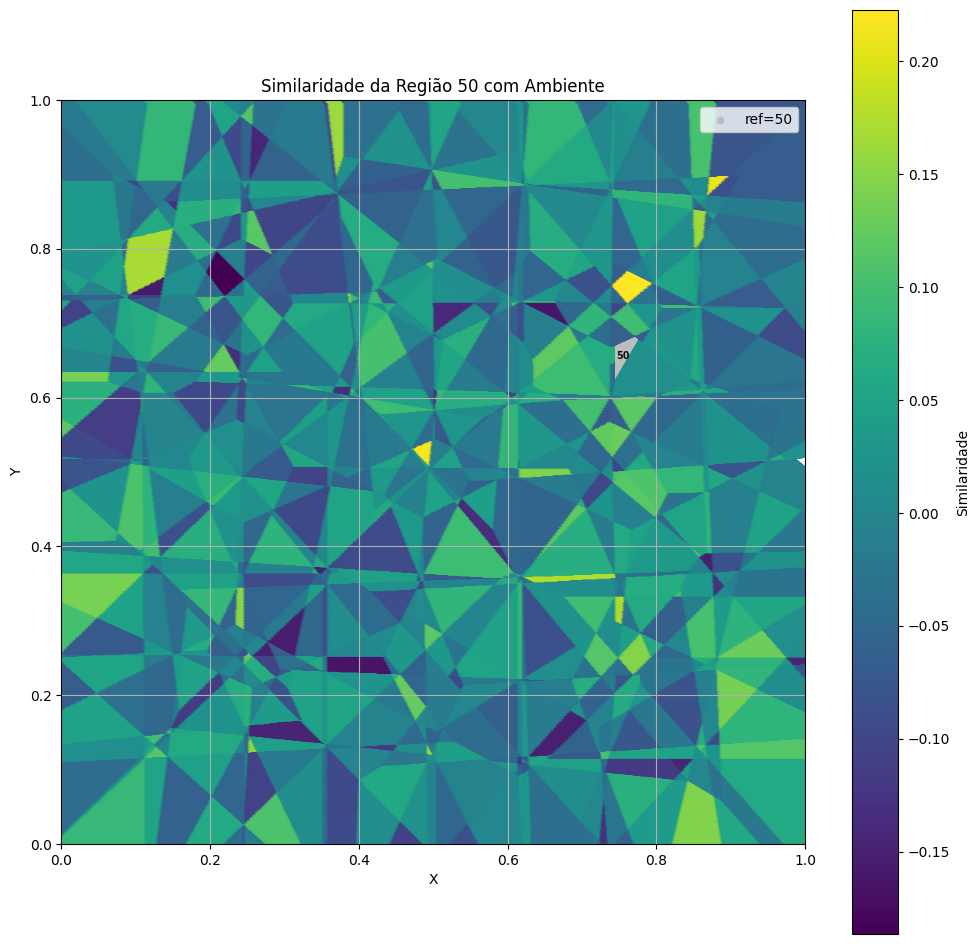

In [14]:
plot_similarity_to_group_from_matrix(apd, coss, grupo_ref=50, cmap="viridis", annotate_means=False)

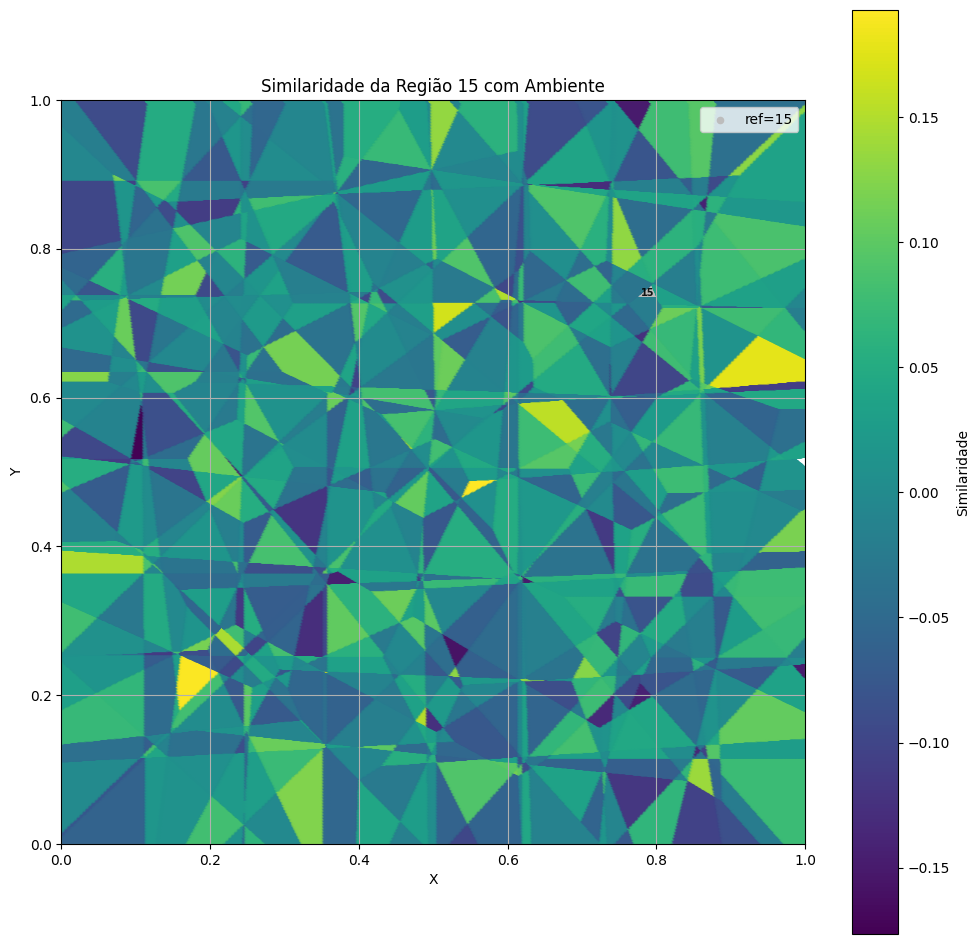

In [24]:
plot_similarity_to_group_from_matrix(apd, coss, grupo_ref=15, cmap="viridis", annotate_means=False)

# Head Projections

In [ ]:
def plot_similarity_to_group_from_projec_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

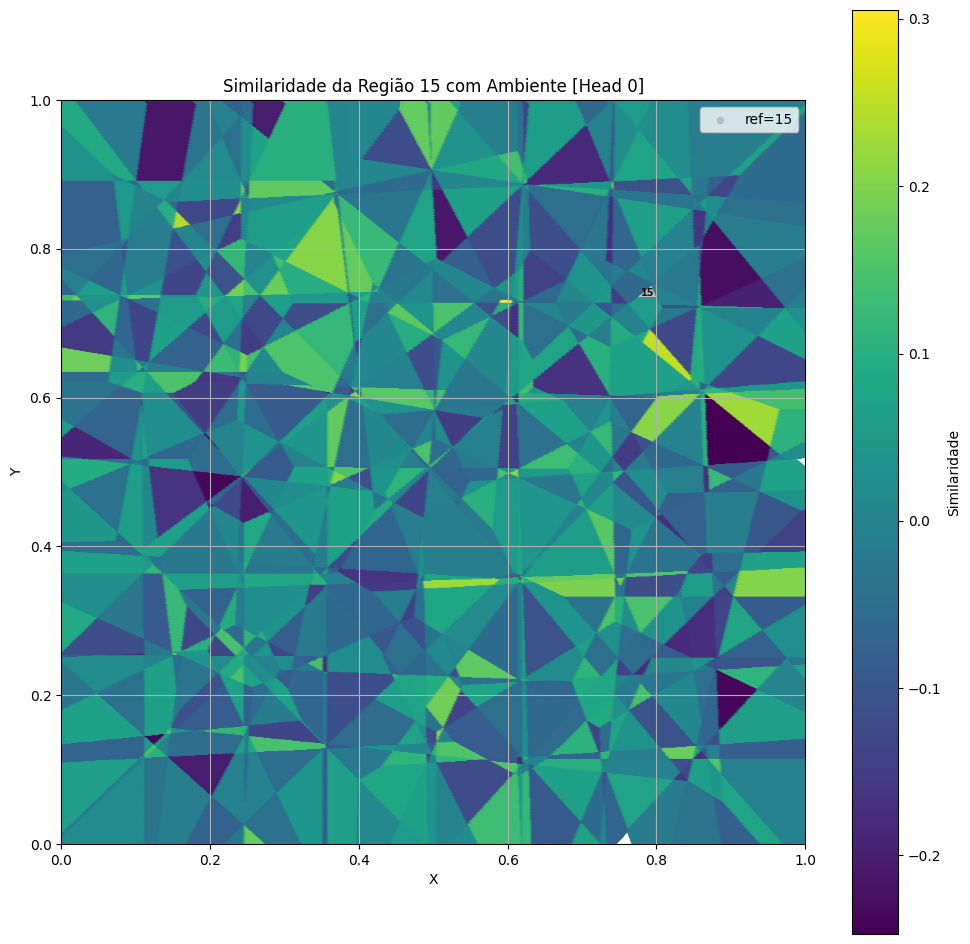

In [19]:
plot_similarity_to_group_from_projec_matrix(apd, head0, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

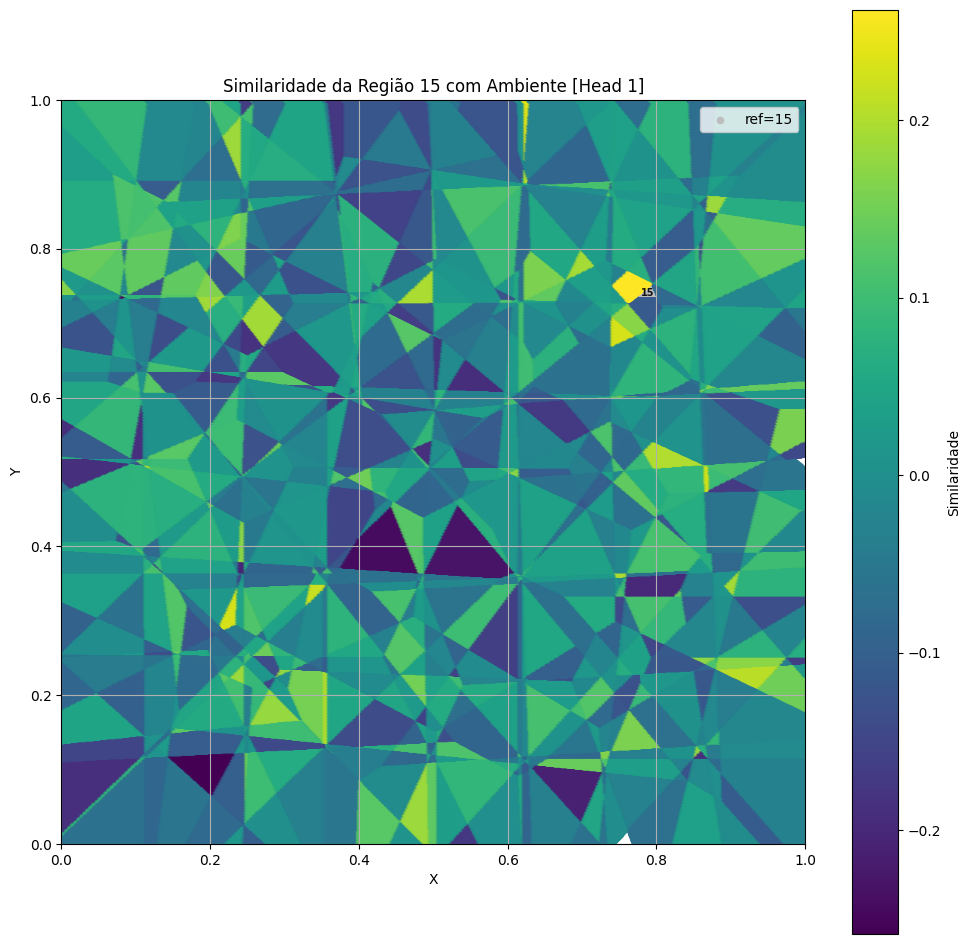

In [20]:
plot_similarity_to_group_from_projec_matrix(apd, head1, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attentions

In [10]:
def plot_similarity_to_group_from_attn_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

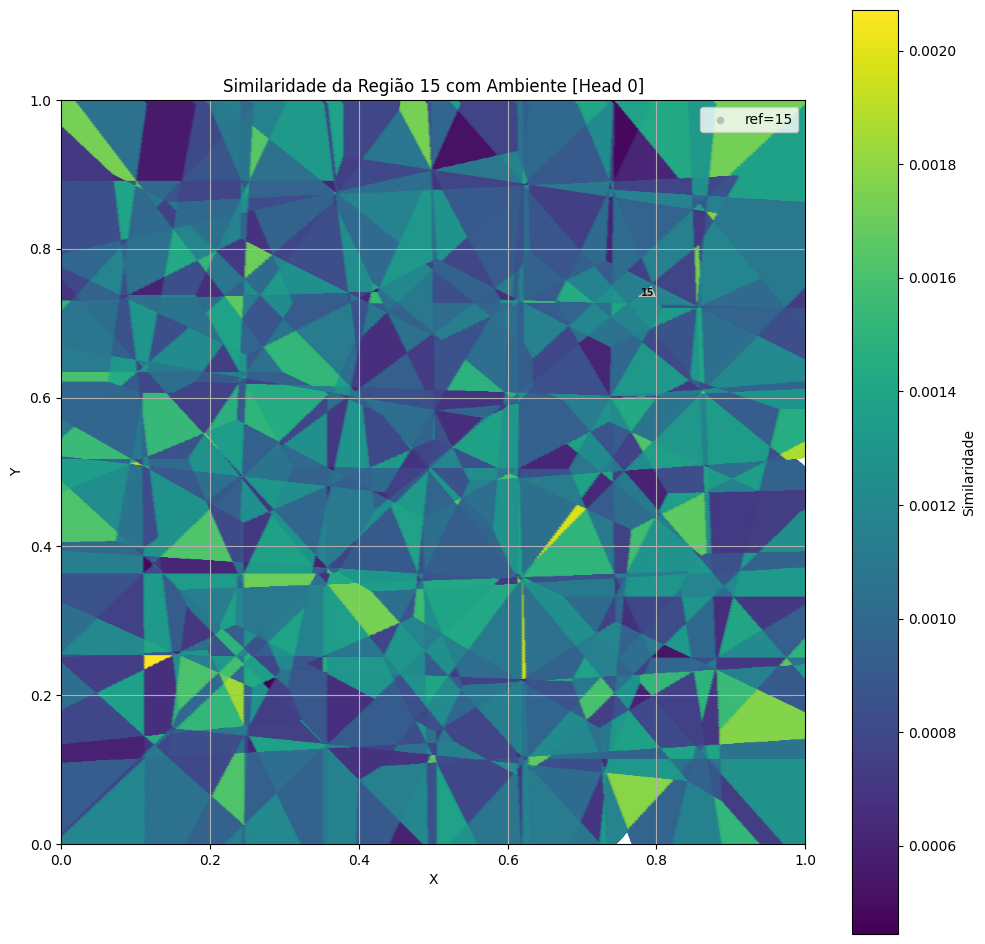

In [11]:
plot_similarity_to_group_from_attn_matrix(apd, head0_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

In [14]:
apd['position_state_id'].max()

1056

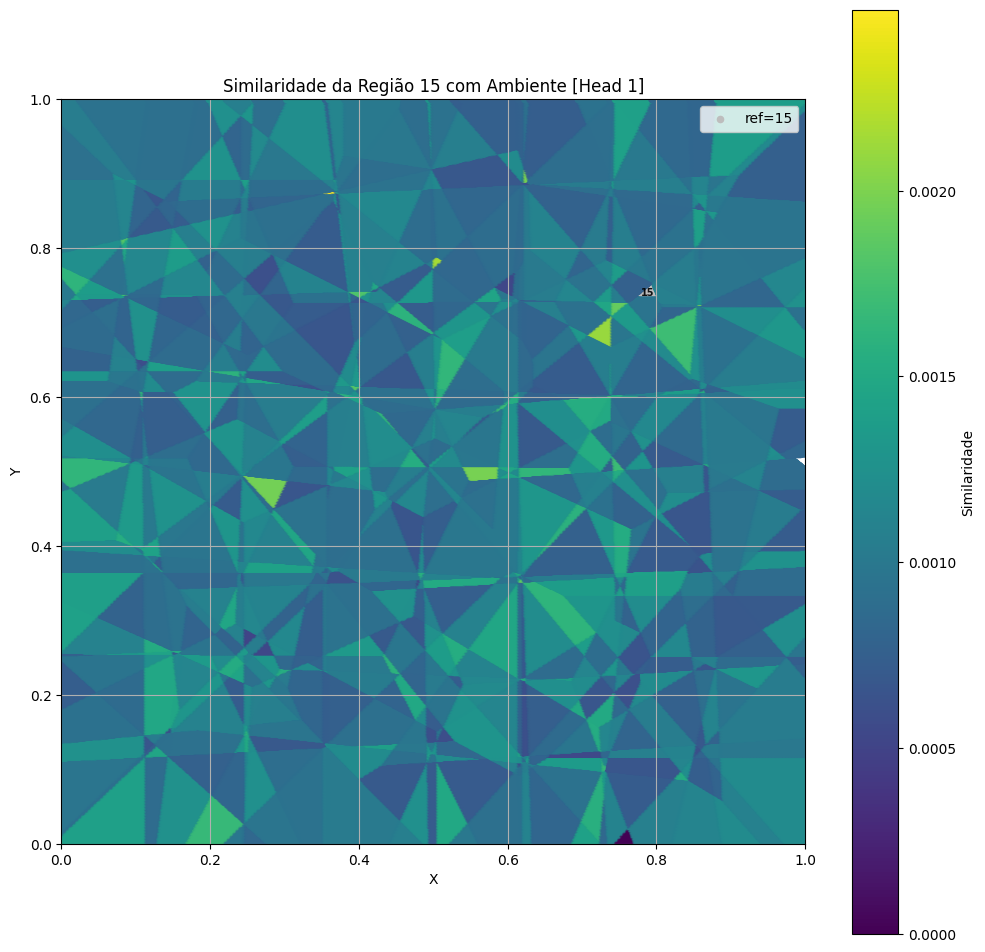

In [12]:
plot_similarity_to_group_from_attn_matrix(apd, head1_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attn w Pos

In [13]:
def plot_similarity_to_group_from_attn_matrix_w_pos(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

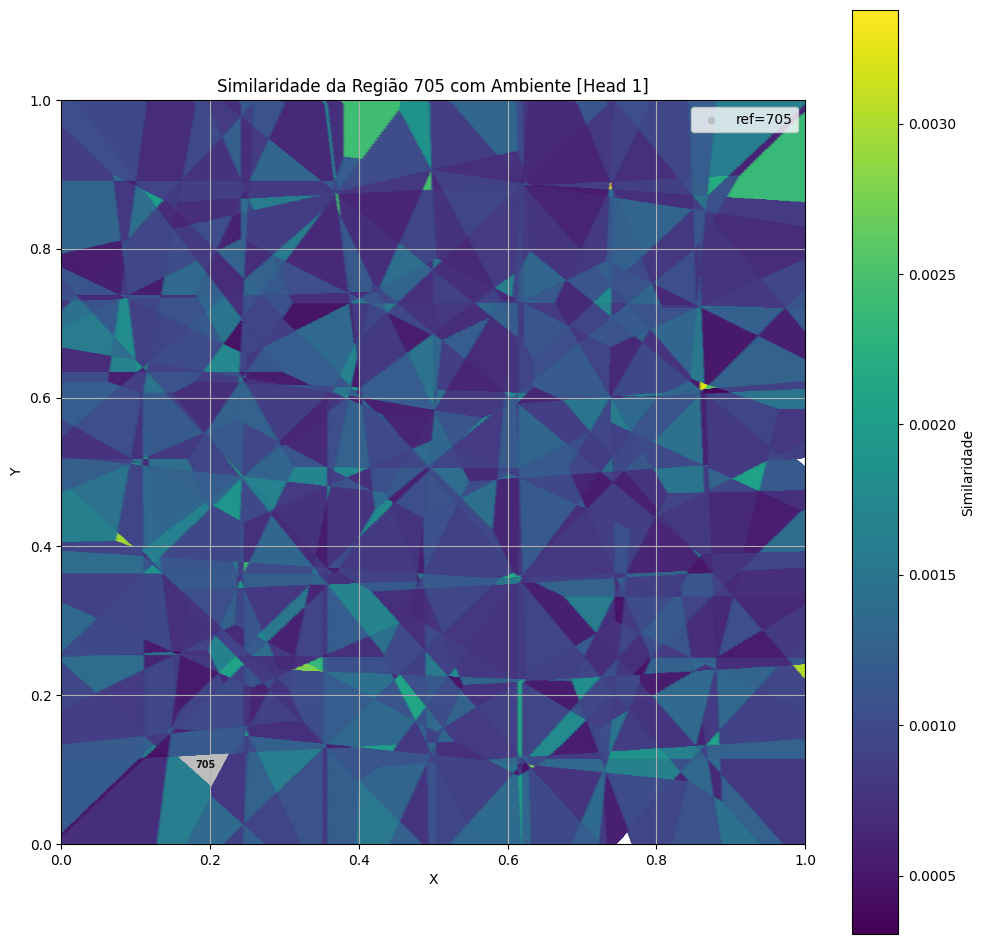

In [22]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1)

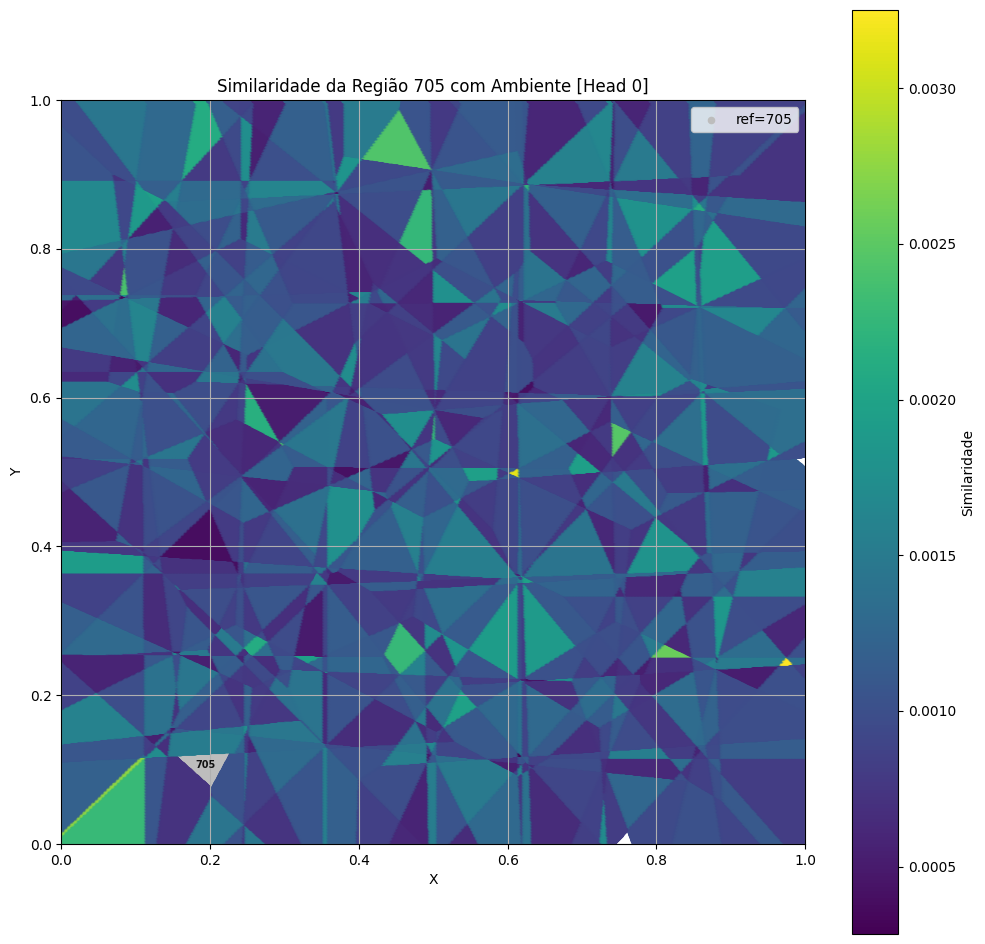

In [23]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0)

In [19]:
# plot_similarity_to_group_from_attn_matrix(apd, head1_att_pos, grupo_ref=806, cmap="viridis", annotate_means=False, num_head=1)

In [ ]:
head1_att_pos.iloc[705].sort_values(ascending=False).head()

341    0.002764
210    0.002684
770    0.002652
667    0.002426
775    0.002383
Name: 15, dtype: float64

In [ ]:
head0_att_pos.iloc[705].sort_values(ascending=False).head()

808    0.004574
138    0.003253
743    0.002719
624    0.002260
446    0.002227
Name: 15, dtype: float64

In [ ]:
head1_att_pos.iloc[15]['806']

0.0027919996

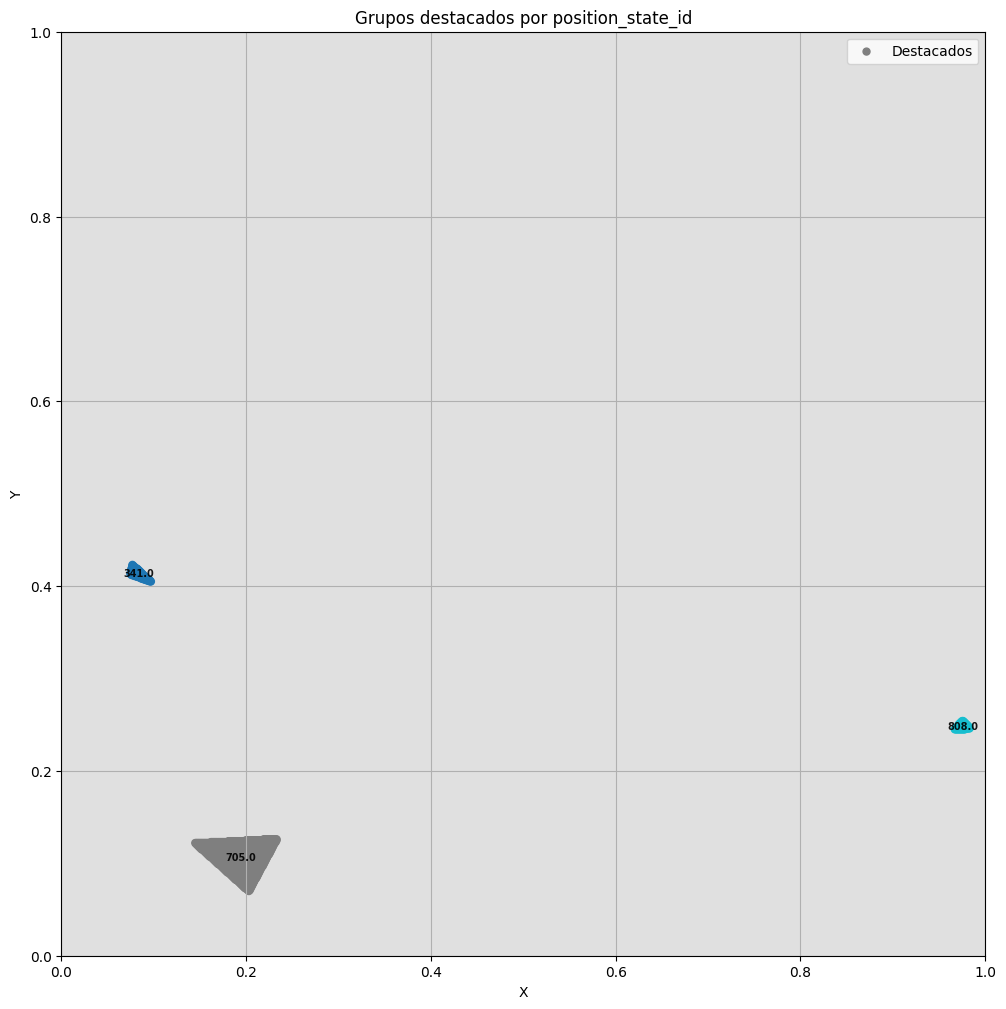

In [24]:
plot_position_states(apd, [705, 341, 808])

# Head Attn W Pos Softmax

In [16]:
def plot_similarity_to_group_from_attn_matrix_w_pos(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
    mode: str='',
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}, {mode}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

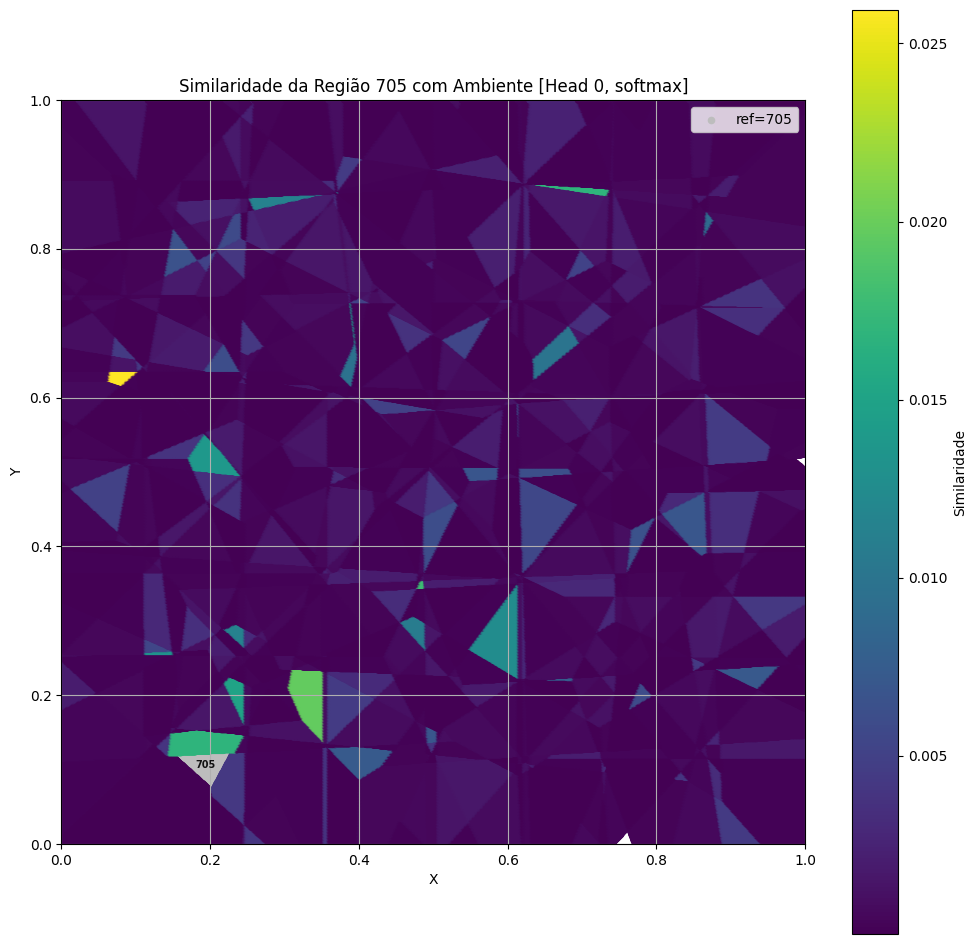

In [19]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_softmax, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='softmax')

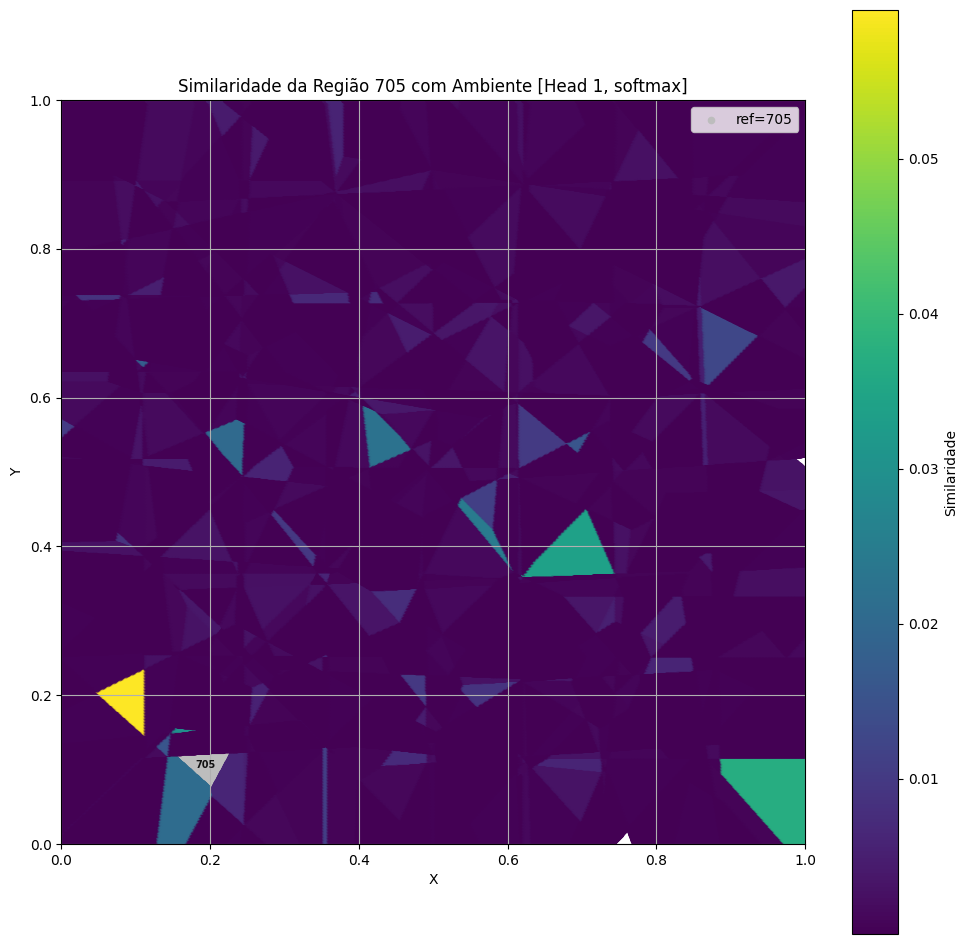

In [18]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_softmax, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='softmax')

# Head Attn W Pos Logit

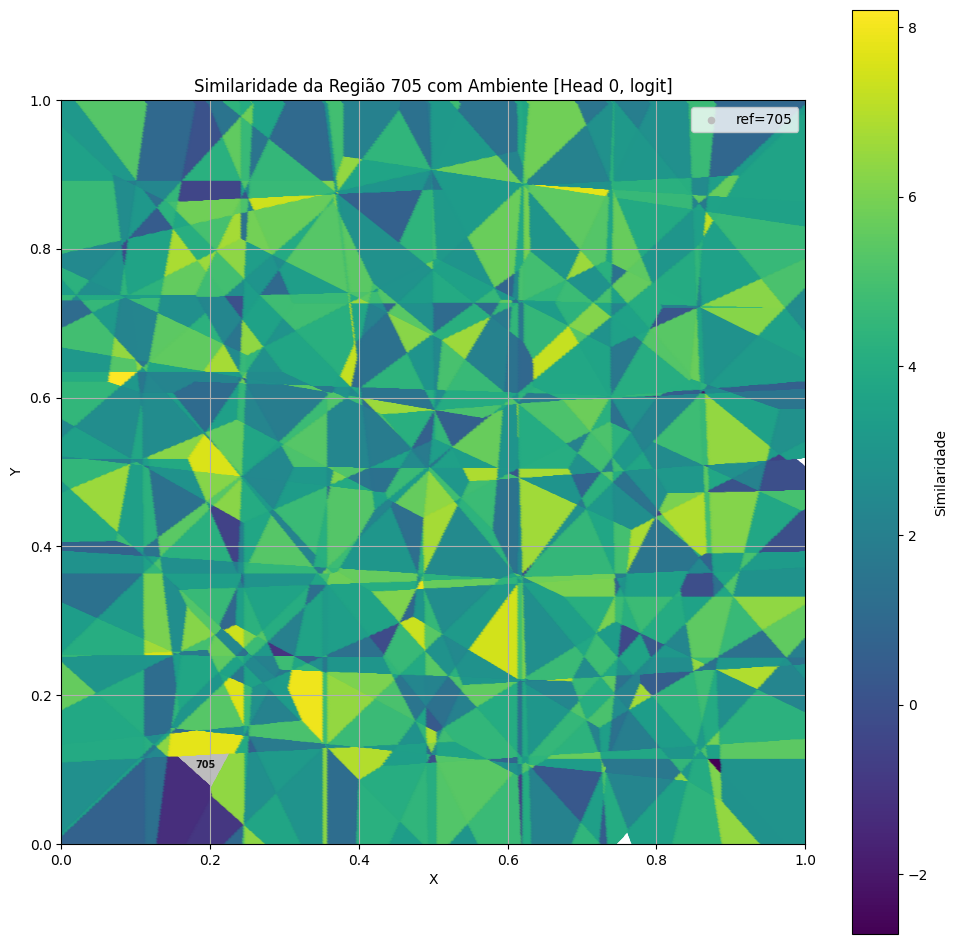

In [20]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_logit, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='logit')

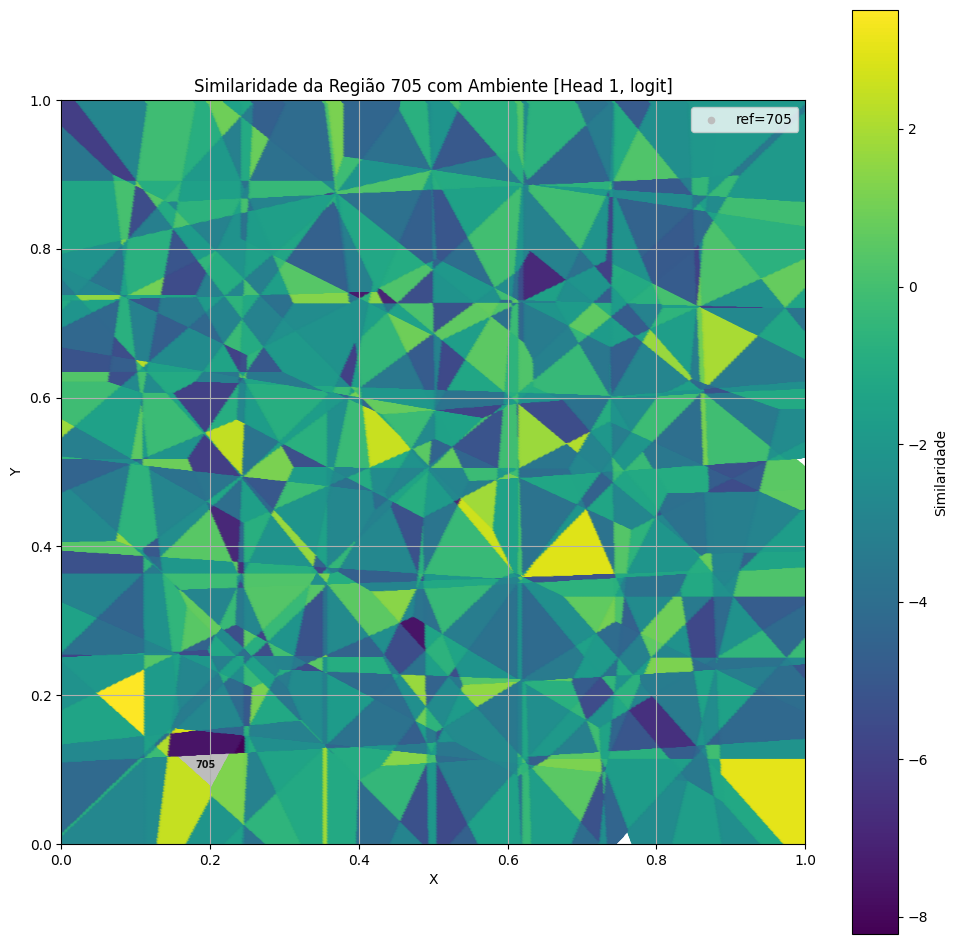

In [21]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_logit, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='logit')

# Head Attn W Pos Cossine

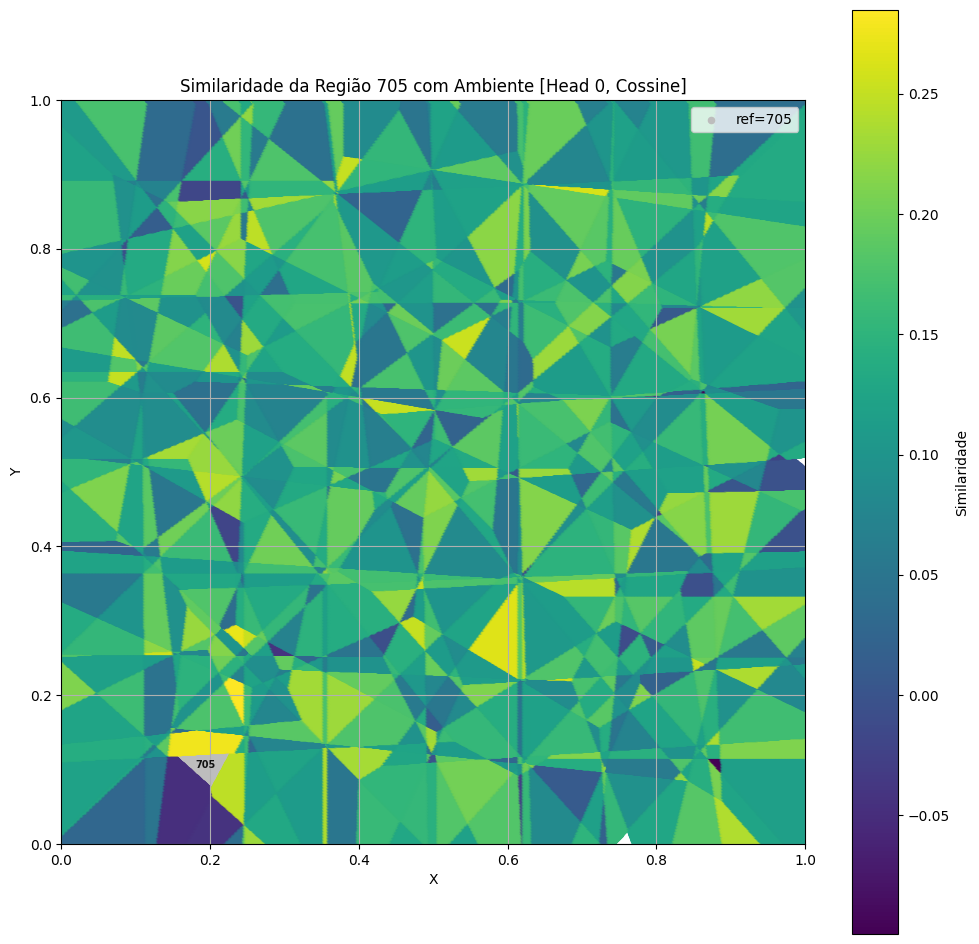

In [23]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_coss, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='Cossine')

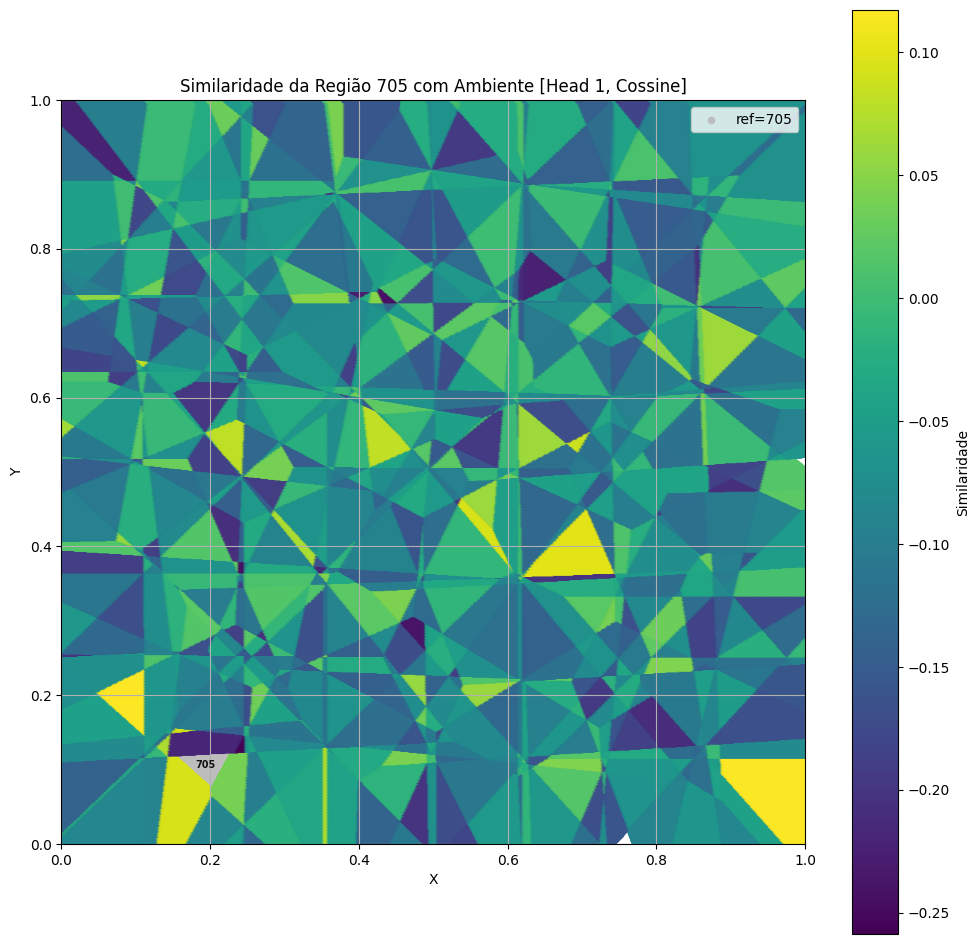

In [22]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_coss, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='Cossine')

# Imgs and GIFs

In [35]:
def gerar_graficos_expansao(
    apd,
    sequencias,
    pasta_destino="imgs",
    titulo_base="Passo",
    dpi=150,
    file_tag: str = '',
    modo: str = "mono",             # "mono" (novo) ou "colormap"
):
    """
    Aceita lista plana OU lista de listas.
    'modo' controla qual função de plot usar: "mono" (novo) ou 
    "colormap".
    """
    # normaliza entrada (plana -> cumulativa)
    if not isinstance(sequencias, (list, tuple)) or len(sequencias) == 0:
        raise ValueError("sequencias deve ser uma lista não vazia (plana ou de listas).")
    is_plana = all(not isinstance(x, (list, tuple)) for x in sequencias)
    sequencias_ids = [list(sequencias[:i+1]) for i in range(len(sequencias))] if is_plana \
                     else [list(s) for s in sequencias]

    os.makedirs(pasta_destino, exist_ok=True)
    caminhos = []
    use_colormap = (modo.lower() == "colormap")

    for step, ids in enumerate(sequencias_ids):
        caminho_arquivo = os.path.join(pasta_destino, f"{file_tag}etapa_{step:02}.png")
        title = f"{titulo_base} {step:02} | {ids[0]}->{ids[-1]}" if len(ids) >= 2 else f"{titulo_base} {step:02}"

        if use_colormap:
            plot_position_states_w_title(apd, grupos_destacados=ids, title=title)
        else:
            plot_position_states_emphasis_w_title(apd, grupos_destacados=ids, title=title)

        plt.savefig(caminho_arquivo, bbox_inches="tight", dpi=dpi)
        plt.close()
        caminhos.append(caminho_arquivo)

    return caminhos

In [36]:
import os, glob, re
from PIL import Image

def gerar_gif(pasta_imagens, file_prefix="", nome_gif="trajetoria_animada.gif", duracao=1000, loop=0):
    """
    Cria um GIF a partir dos PNGs em `pasta_imagens` cujo nome COMEÇA com `file_prefix`.

    Ex.: se você salvou como f"{file_tag}etapa_{step:02}.png",
         passe `file_prefix=file_tag` para pegar só esses frames.

    Parâmetros:
    - pasta_imagens : str | Path
    - file_prefix   : str  (prefixo do arquivo; ex.: "runA_" -> "runA_etapa_00.png")
    - nome_gif      : str  (nome do GIF final; salvo dentro de `pasta_imagens`)
    - duracao       : int  (ms entre frames)
    - loop          : int  (0 = infinito)

    Retorna:
    - caminho do GIF salvo (str) ou None se não encontrou imagens.
    """
    if not os.path.isdir(pasta_imagens):
        raise FileNotFoundError(f"Pasta não encontrada: {pasta_imagens}")

    padrao = os.path.join(pasta_imagens, f"{file_prefix}*.png")
    arquivos = glob.glob(padrao)

    if not arquivos:
        print(f"Nenhuma imagem encontrada com prefixo '{file_prefix}' em {pasta_imagens}.")
        return None

    # ordena por número de etapa_XX; se não casar, ordena por nome
    def key_etapa(p):
        m = re.search(r"etapa_(\d+)\.png$", os.path.basename(p))
        return (0, int(m.group(1))) if m else (1, os.path.basename(p))

    arquivos = sorted(arquivos, key=key_etapa)

    # carrega frames
    frames = [Image.open(p) for p in arquivos]
    try:
        out_path = os.path.join(pasta_imagens, nome_gif)
        frames[0].save(
            out_path,
            save_all=True,
            append_images=frames[1:],
            duration=duracao,
            loop=loop,
            optimize=True,
            disposal=2,   # ajuda a evitar ghosting entre frames
        )
        print(f"GIF salvo: {out_path}  ({len(frames)} frames)")
        return out_path
    finally:
        for im in frames:
            try:
                im.close()
            except Exception:
                pass


In [ ]:
[15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61]

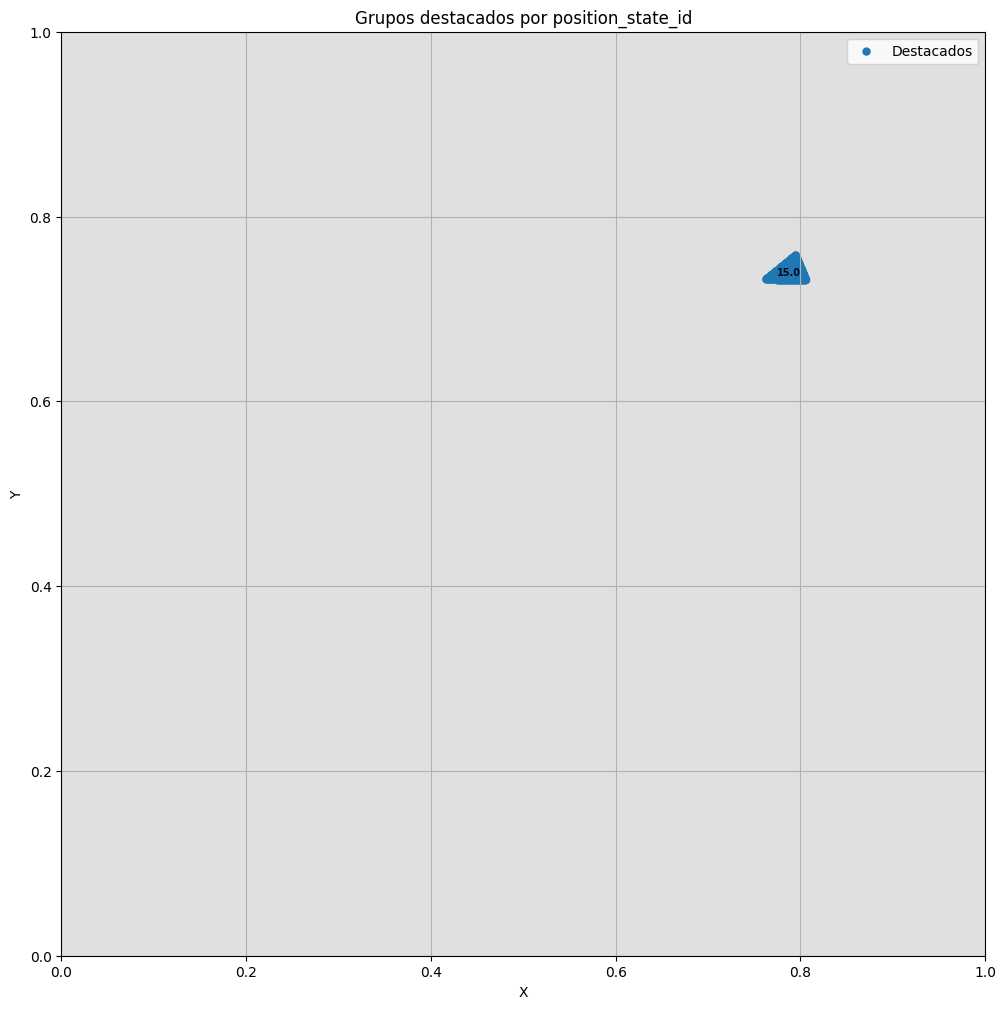

In [26]:
plot_position_states(apd, [15])

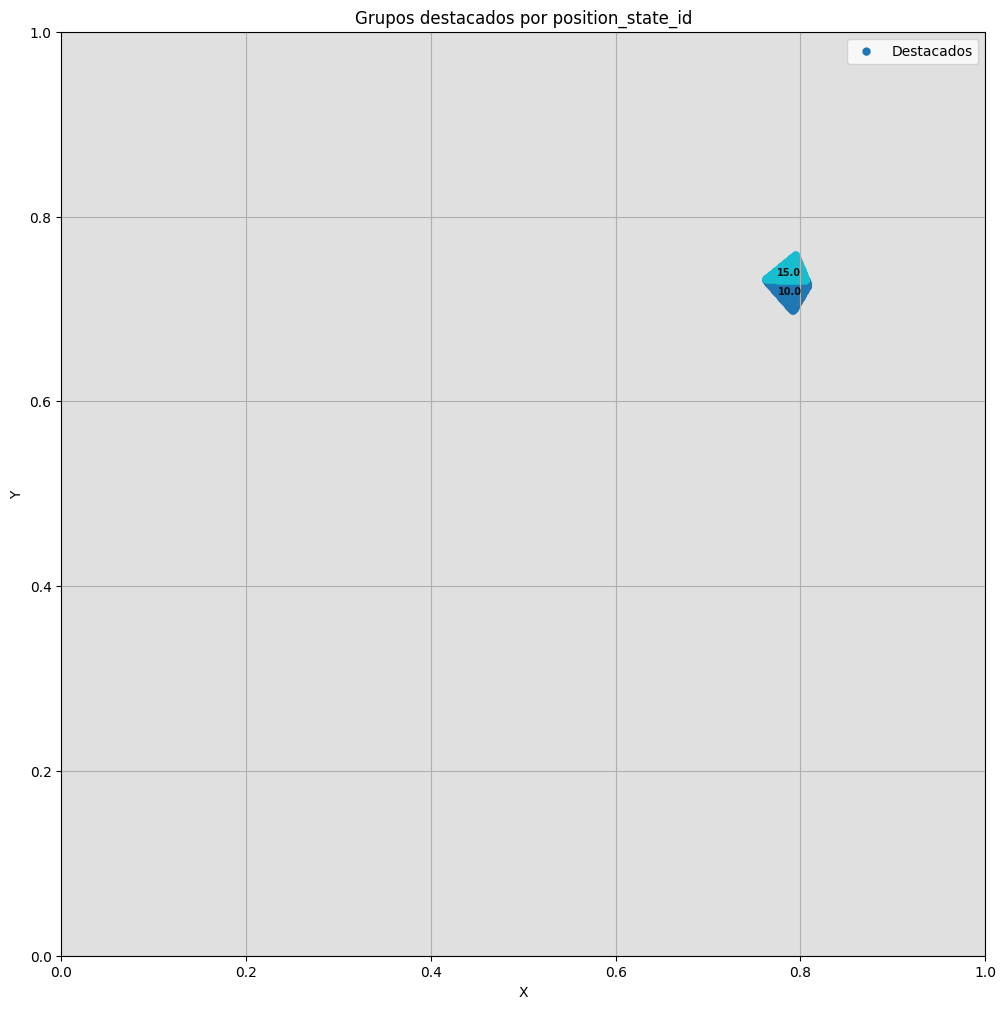

In [27]:
plot_position_states(apd, [15, 10])

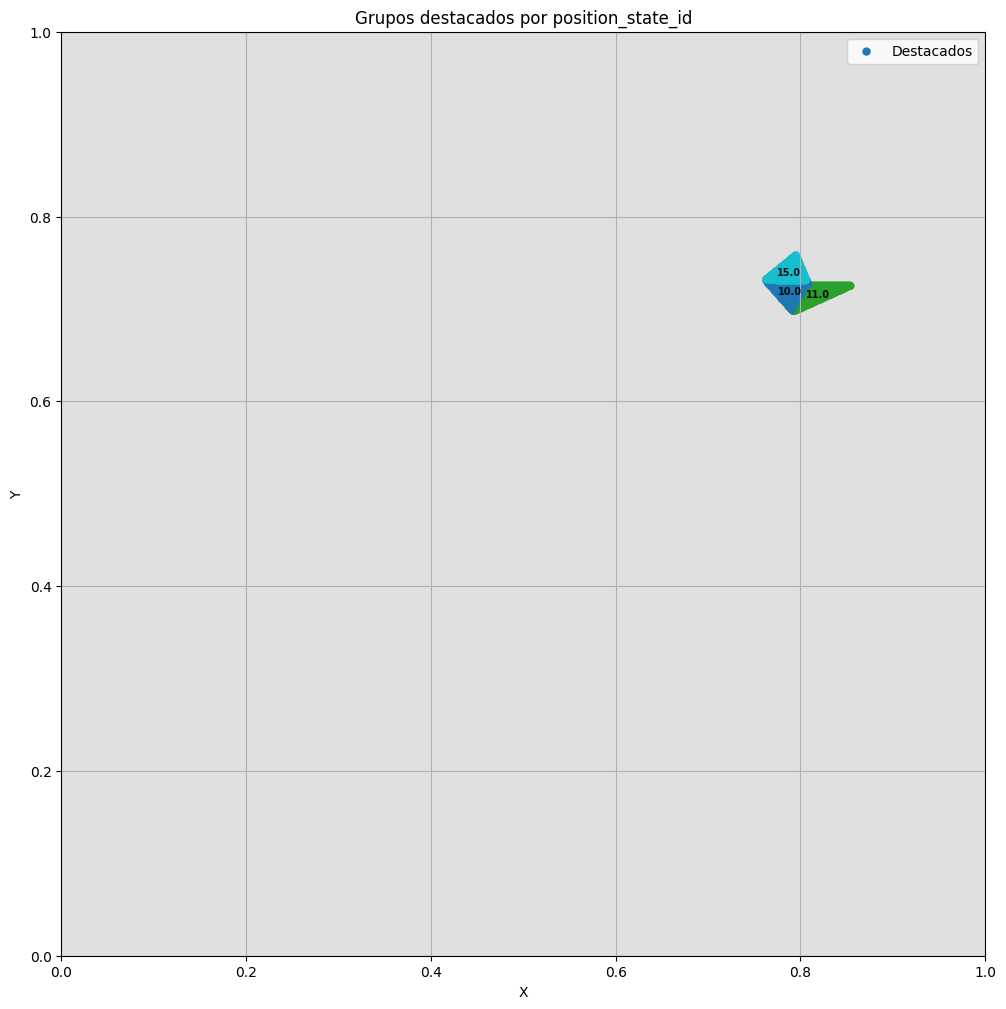

In [29]:
plot_position_states(apd, [15, 10, 11])

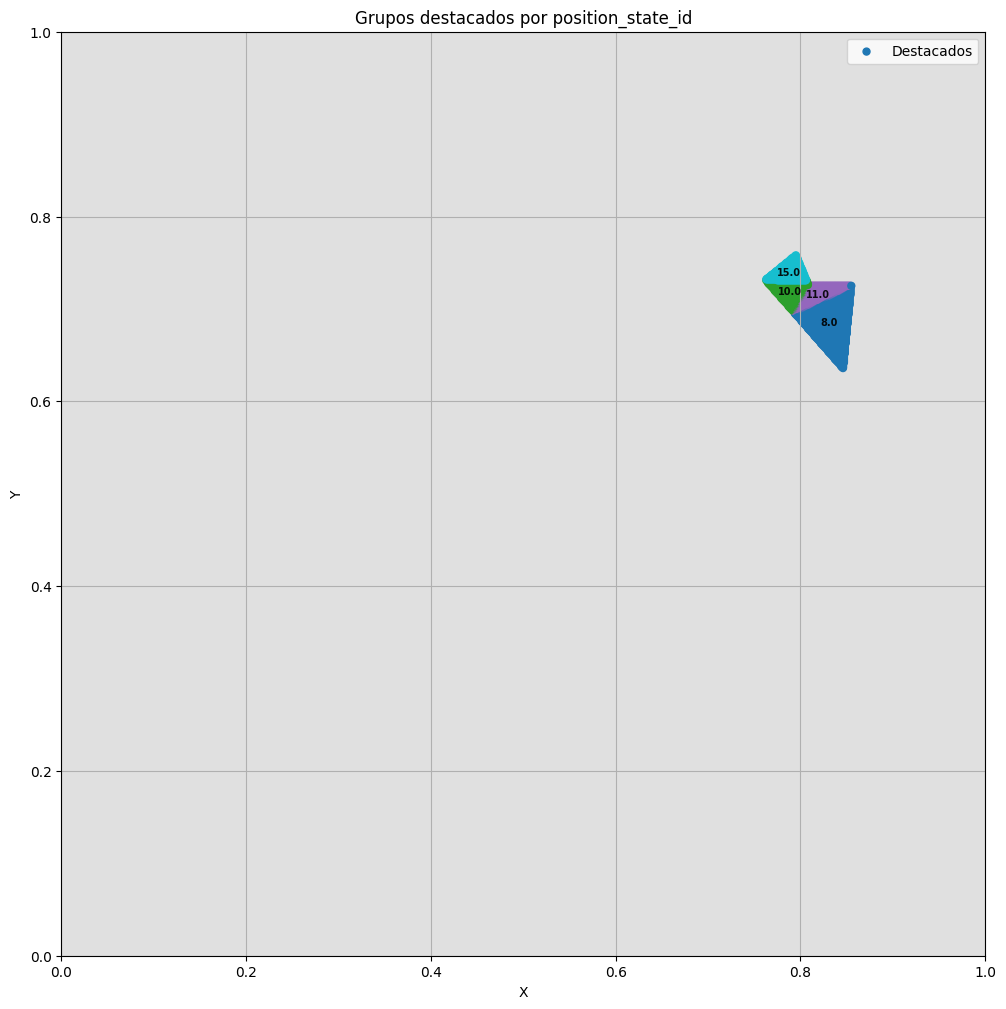

In [30]:
plot_position_states(apd, [15, 10, 11, 8])

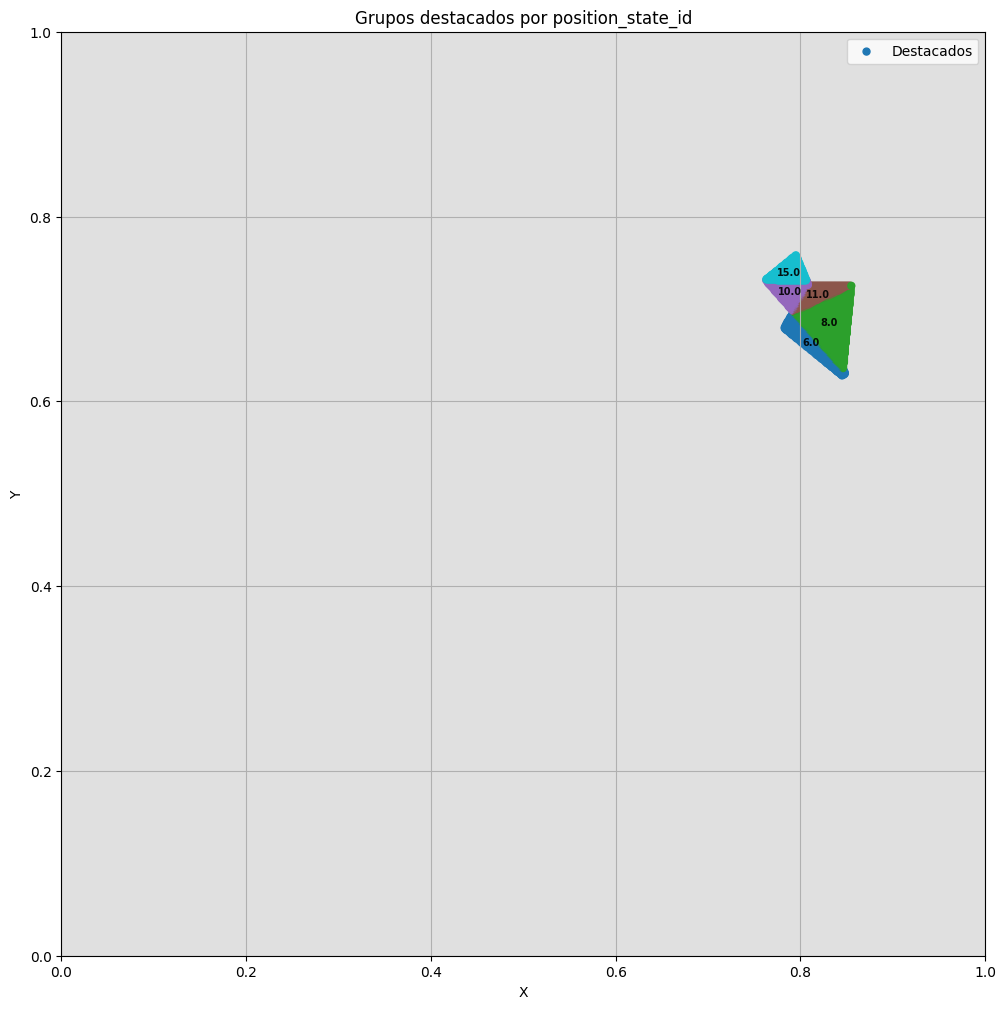

In [31]:
plot_position_states(apd, [15, 10, 11, 8, 6])

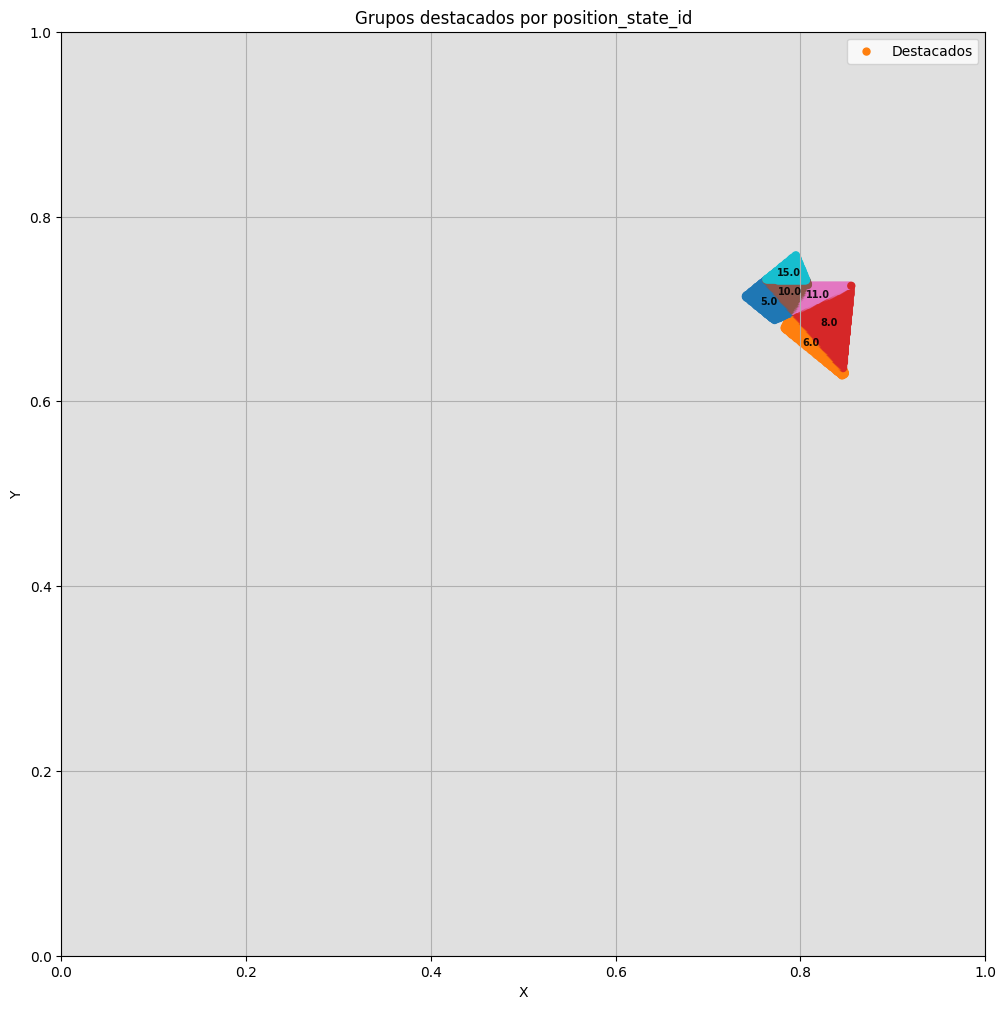

In [32]:
plot_position_states(apd, [15, 10, 11, 8, 6, 5])

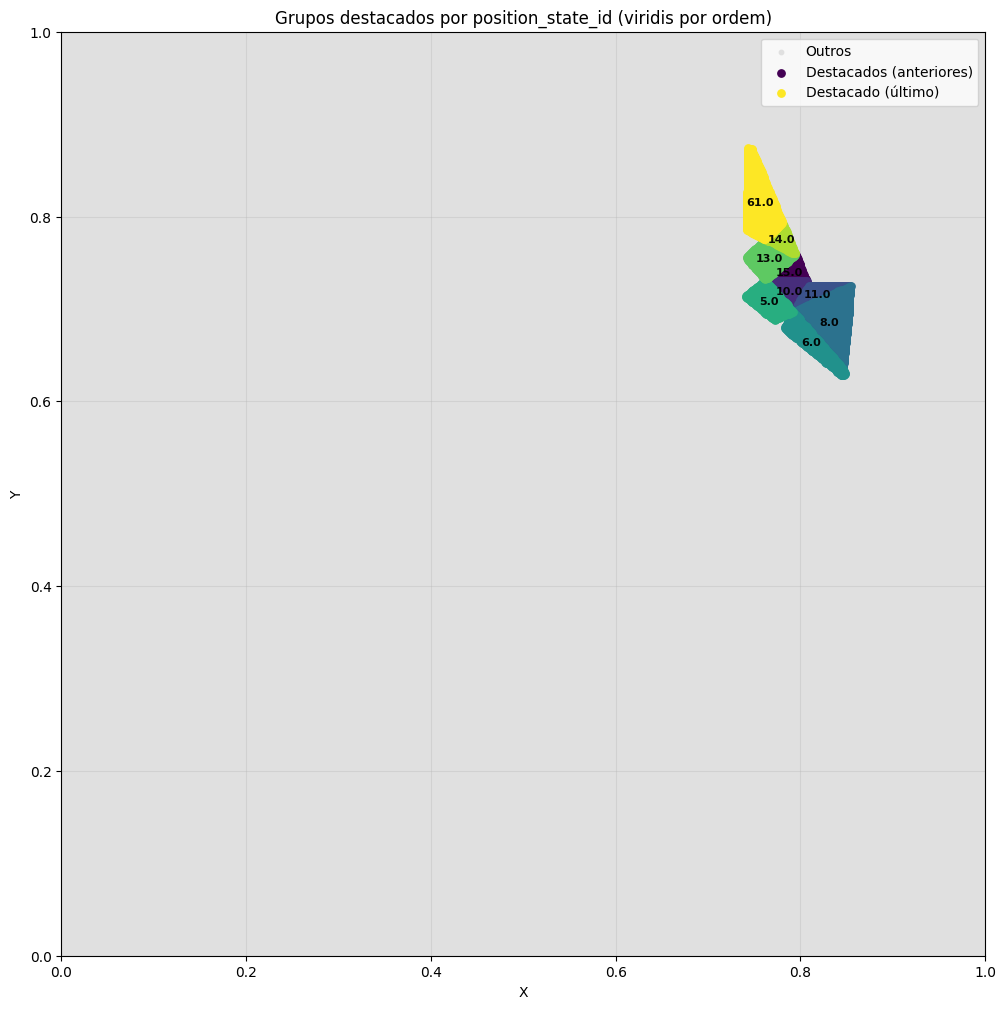

In [ ]:
plot_position_states_w_title(apd, [15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61])

In [19]:
gerar_graficos_expansao(apd, [15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61], titulo_base='Exemplo', modo='mono', file_tag='test_')

['imgs/test_etapa_00.png',
 'imgs/test_etapa_01.png',
 'imgs/test_etapa_02.png',
 'imgs/test_etapa_03.png',
 'imgs/test_etapa_04.png',
 'imgs/test_etapa_05.png',
 'imgs/test_etapa_06.png',
 'imgs/test_etapa_07.png',
 'imgs/test_etapa_08.png',
 'imgs/test_etapa_09.png',
 'imgs/test_etapa_10.png']

In [37]:
gerar_graficos_expansao(apd, [705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512], titulo_base='Exemplo', modo='mono', file_tag='test705_')

['imgs/test705_etapa_00.png',
 'imgs/test705_etapa_01.png',
 'imgs/test705_etapa_02.png',
 'imgs/test705_etapa_03.png',
 'imgs/test705_etapa_04.png',
 'imgs/test705_etapa_05.png',
 'imgs/test705_etapa_06.png',
 'imgs/test705_etapa_07.png',
 'imgs/test705_etapa_08.png',
 'imgs/test705_etapa_09.png',
 'imgs/test705_etapa_10.png']

In [39]:
# Se gerou com file_tag="GPT_Passo_"
gerar_gif("imgs", file_prefix="test_", nome_gif="test_trajetoria_gpt.gif", duracao=600, loop=0)

GIF salvo: imgs/test_trajetoria_gpt.gif  (11 frames)


'imgs/test_trajetoria_gpt.gif'

In [40]:
# Se gerou com file_tag="GPT_Passo_"
gerar_gif("imgs", file_prefix="test705_", nome_gif="test705_trajetoria_gpt.gif", duracao=600, loop=0)

GIF salvo: imgs/test705_trajetoria_gpt.gif  (11 frames)


'imgs/test705_trajetoria_gpt.gif'

# Probs Distribs

In [20]:
def plot_prob_from_probs_df_w_pos(
    apd: pd.DataFrame,
    probs_df: pd.DataFrame,     # index: token_id (int ou str numérica), columns: "Passo 01", ...
    passo,                      # str ("Passo 04") OU int (0 = primeira coluna)
    token_atual: int,           # id do token atual (marcado em cinza quando colorir_token_atual_por_prob=False)
    cmap: str = "viridis",
    annotate_means: bool = False,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head: int = 0,
    mode: str = "",
    colorir_token_atual_por_prob: bool = False,   # <--- NOVO
):
    """
    Colore os pontos de `apd` pela probabilidade do token no `passo` escolhido.
    Se `colorir_token_atual_por_prob=True`, o `token_atual` NÃO é pintado de cinza
    e sim colorido conforme a sua probabilidade, apenas com anotação do id.
    """
    # --- saneamento: garantir que o índice (tokens) seja int compatível com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        return df

    probs_df = _to_int_index(probs_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"

    # resolve a coluna do passo
    col = probs_df.columns[passo] if isinstance(passo, int) else passo
    if col not in probs_df.columns:
        raise ValueError(f"Coluna '{col}' não encontrada em probs_df")

    # separa atual e demais
    is_ref = (apd["position_state_id"] == token_atual)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de probabilidades no passo escolhido (indexada por id)
    prob_series = probs_df[col]  # pandas Series: index = ids, values = probs

    # mapeia probabilidade
    df_outros["prob"] = df_outros["position_state_id"].map(prob_series)

    # --- decide o conjunto que será colorido por probabilidade ---
    if colorir_token_atual_por_prob:
        if not df_ref.empty:
            df_ref_col = df_ref.copy()
            df_ref_col["prob"] = df_ref_col["position_state_id"].map(prob_series)
            data_to_scatter = pd.concat([df_outros, df_ref_col], ignore_index=True)
        else:
            data_to_scatter = df_outros
    else:
        data_to_scatter = df_outros

    # plot
    plt.figure(figsize=(12, 12))

    # 1) token atual:
    if not colorir_token_atual_por_prob:
        # pinta em cinza + anota
        if not df_ref.empty:
            plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"token={token_atual}")
            plt.annotate(str(token_atual),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)
    else:
        # não pinta cinza; apenas anota (ele será colorido por prob no scatter abaixo)
        if not df_ref.empty:
            plt.annotate(str(token_atual),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) coloridos por probabilidade (NaN em 'prob' são ignorados pelo scatter)
    if not data_to_scatter.empty:
        sc = plt.scatter(
            data_to_scatter["X"], data_to_scatter["Y"],
            c=data_to_scatter["prob"], cmap=cmap, s=s_outros
        )
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Probabilidade ({col})")

    # 3) anotação das médias por grupo (≠ token atual)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X"); plt.ylabel("Y")
    plt.title(f"Probabilidade no {col}")
    plt.xlim(0, 1); plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")

    # legenda (só aparece se algo tiver label — ex.: token cinza quando aplicável)
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        plt.legend(handles, labels, loc="upper right")

    plt.show()


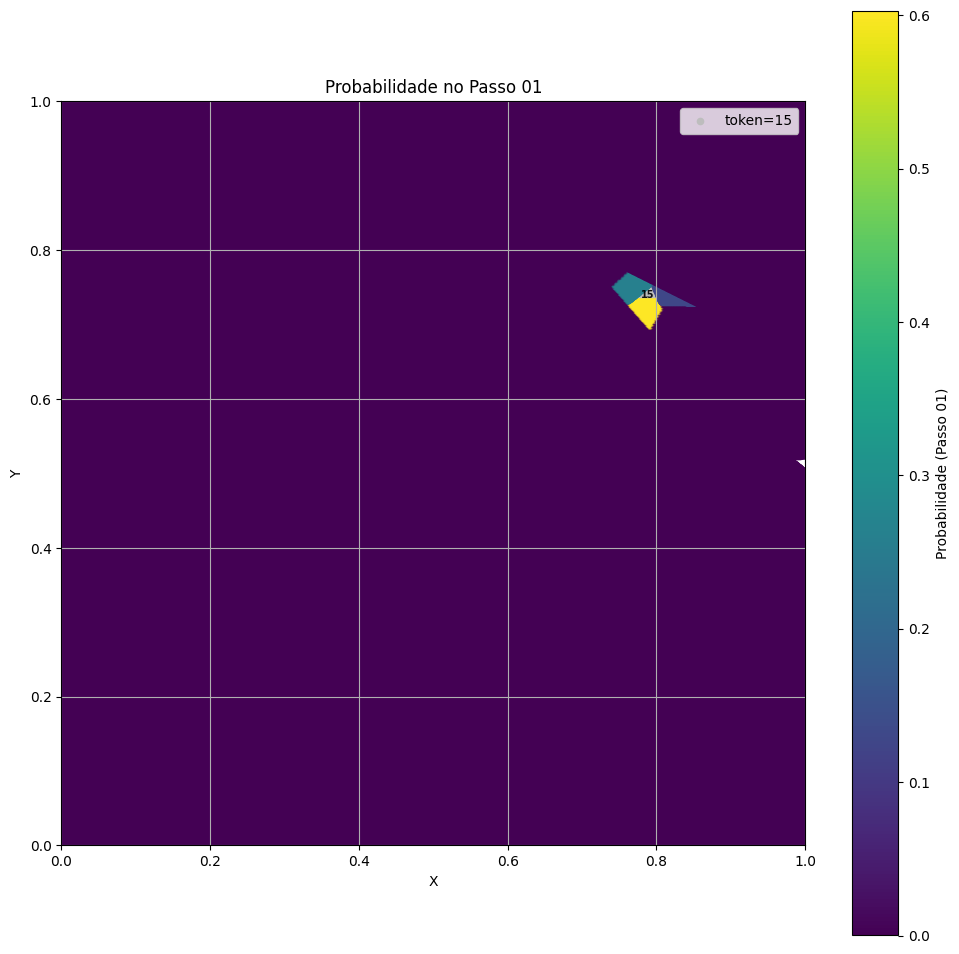

In [21]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=0, token_atual=15,)

In [23]:
distribs_probs.head()

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.662680e-06,3.177991e-06,4.009456e-06,1.145890e-06,2.520847e-06,0.000004,5.748174e-06,8.418958e-06,1.464796e-07,0.000228
1,2.157076e-07,1.543836e-07,1.201682e-07,5.364881e-08,7.375746e-07,0.000002,4.088467e-07,4.277045e-07,1.134515e-08,0.000080
2,1.828289e-04,1.275089e-05,1.952099e-06,6.359525e-07,6.182945e-04,0.000040,6.925649e-05,3.427698e-05,2.078097e-08,0.000072
3,7.179261e-06,5.824850e-01,8.121820e-05,5.431971e-01,3.116338e-06,0.000618,9.700832e-04,7.698964e-04,1.833539e-07,0.000396
4,1.745968e-05,2.277800e-05,6.613256e-06,8.439538e-06,5.750006e-06,0.000010,5.122279e-06,3.306124e-06,5.105923e-08,0.000084


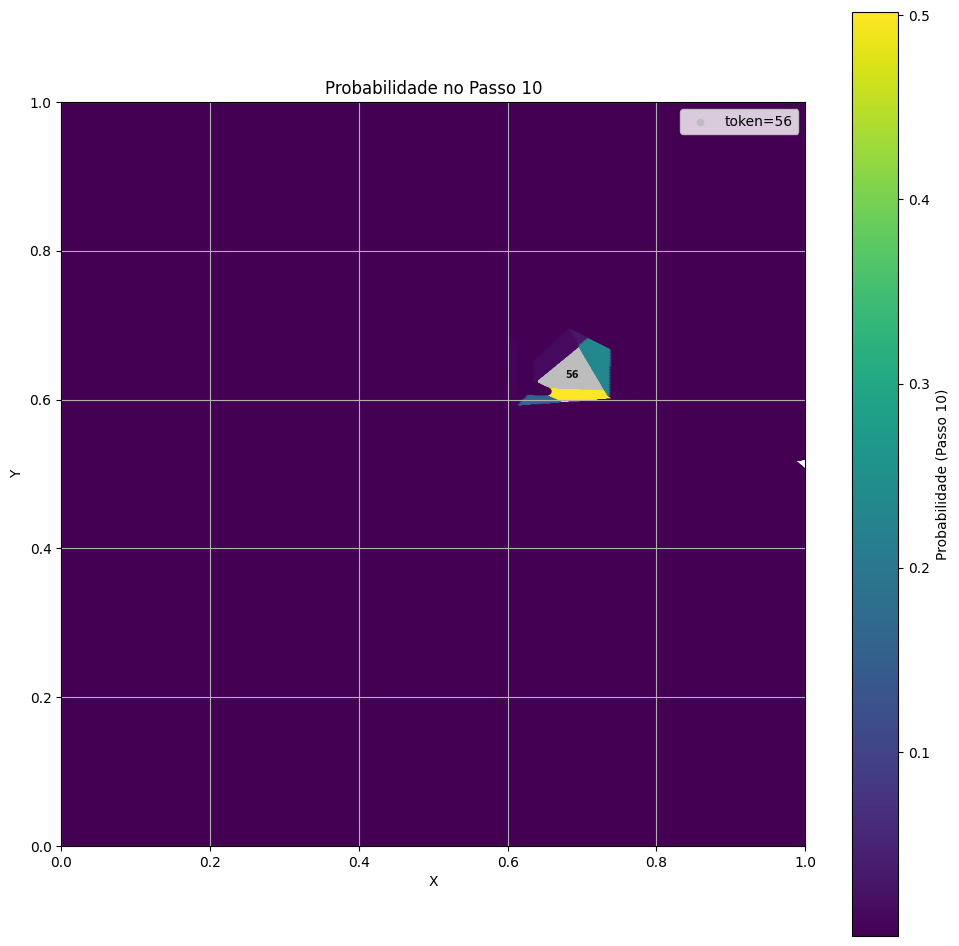

In [26]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=9, token_atual=56,)

In [32]:
[705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512]

[705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512]

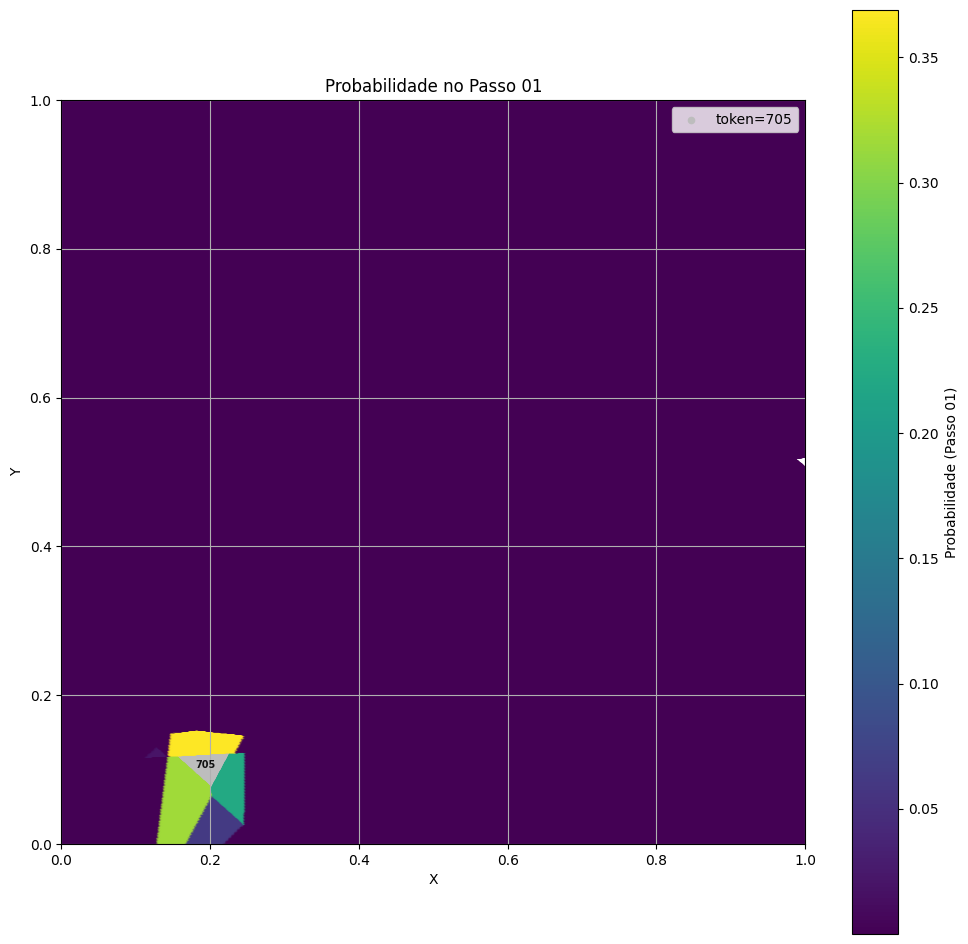

In [31]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=0, token_atual=705,)

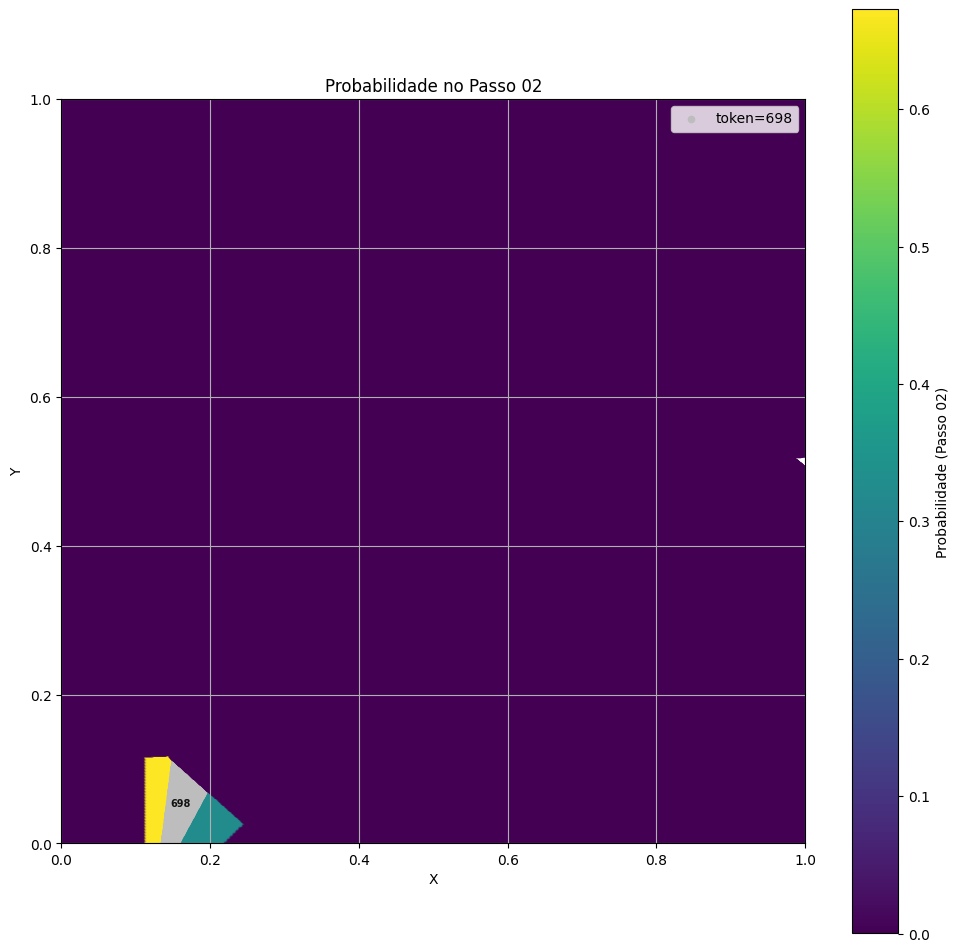

In [33]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=1, token_atual=698,)

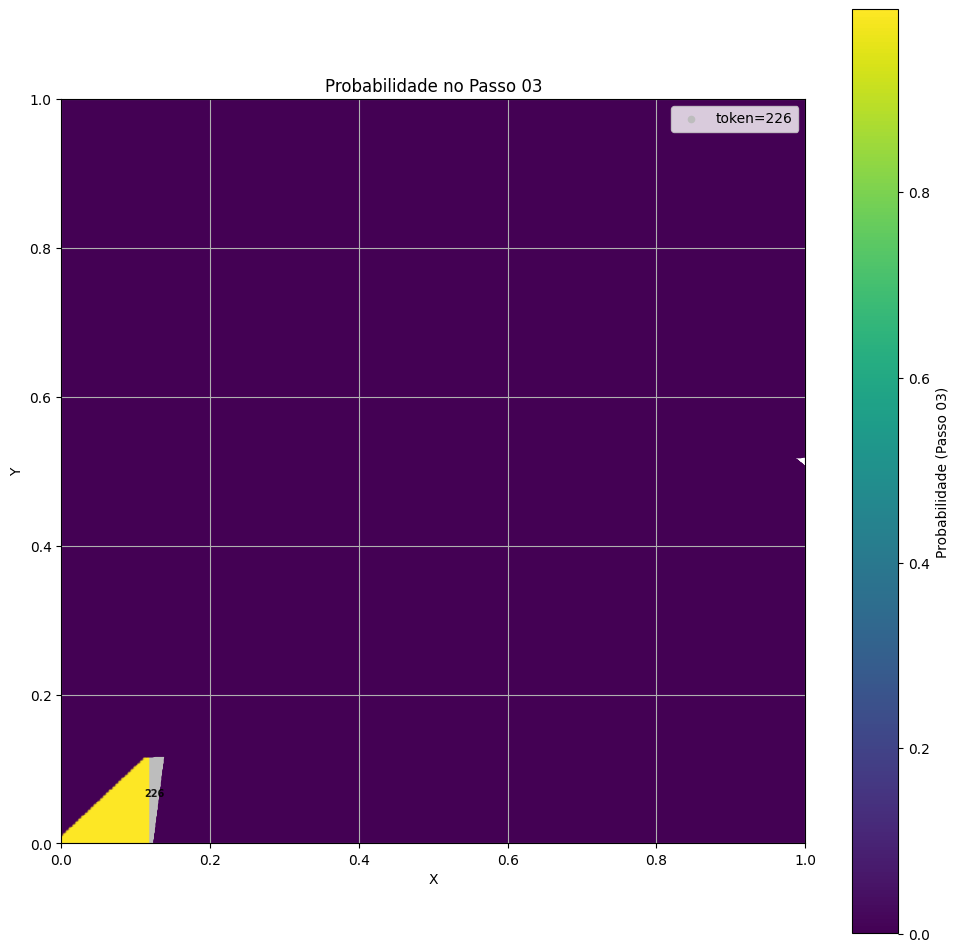

In [41]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=2, token_atual=226,)

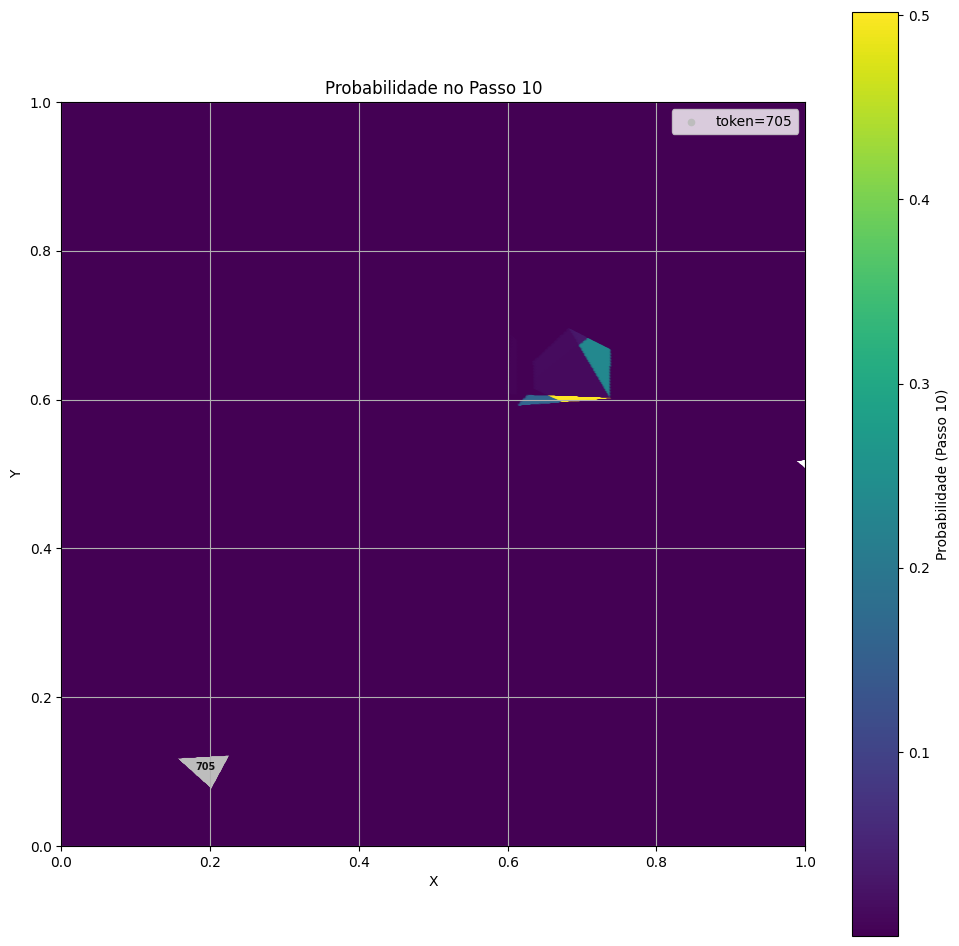

In [27]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=9, token_atual=705,)

# Logits Distrib

In [15]:
def plot_logits_from_logits_df_w_pos(
    apd: pd.DataFrame,
    logits_df: pd.DataFrame,    # index: token_id (int ou str numérica), columns: "Passo 01", ...
    passo,                      # str ("Passo 04") OU int (0 = primeira coluna)
    token_atual: int,           # id do token atual (marcado em cinza)
    cmap: str = "viridis",
    annotate_means: bool = False,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head: int = 0,
    mode: str = "",
):
    """
    Colore os pontos de `apd` pelo **logit** do token no `passo` escolhido.
    O `token_atual` é plotado em cinza.
    """
    # --- saneamento: garantir que o índice (tokens) seja int compatível com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        return df

    logits_df = _to_int_index(logits_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"

    # resolve a coluna do passo
    col = logits_df.columns[passo] if isinstance(passo, int) else passo
    if col not in logits_df.columns:
        raise ValueError(f"Coluna '{col}' não encontrada em logits_df")

    # separa atual e demais
    is_ref = (apd["position_state_id"] == token_atual)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de logits no passo escolhido (indexada por id)
    logit_series = logits_df[col]

    # mapeia cada position_state_id -> logit no passo; ids ausentes viram NaN
    # substitui ±inf (ex.: após top-k) por NaN para o scatter ignorar
    df_outros["logit"] = df_outros["position_state_id"].map(logit_series).replace([np.inf, -np.inf], np.nan)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) token atual em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"token={token_atual}")
        plt.annotate(str(token_atual),
                     (df_ref["X"].mean(), df_ref["Y"].mean()),
                     fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pelo logit (NaN são ignorados pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["logit"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Logit ({col})")

    # 3) anotação das médias por grupo (≠ token atual)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Logits de Cada Região no {col}")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()


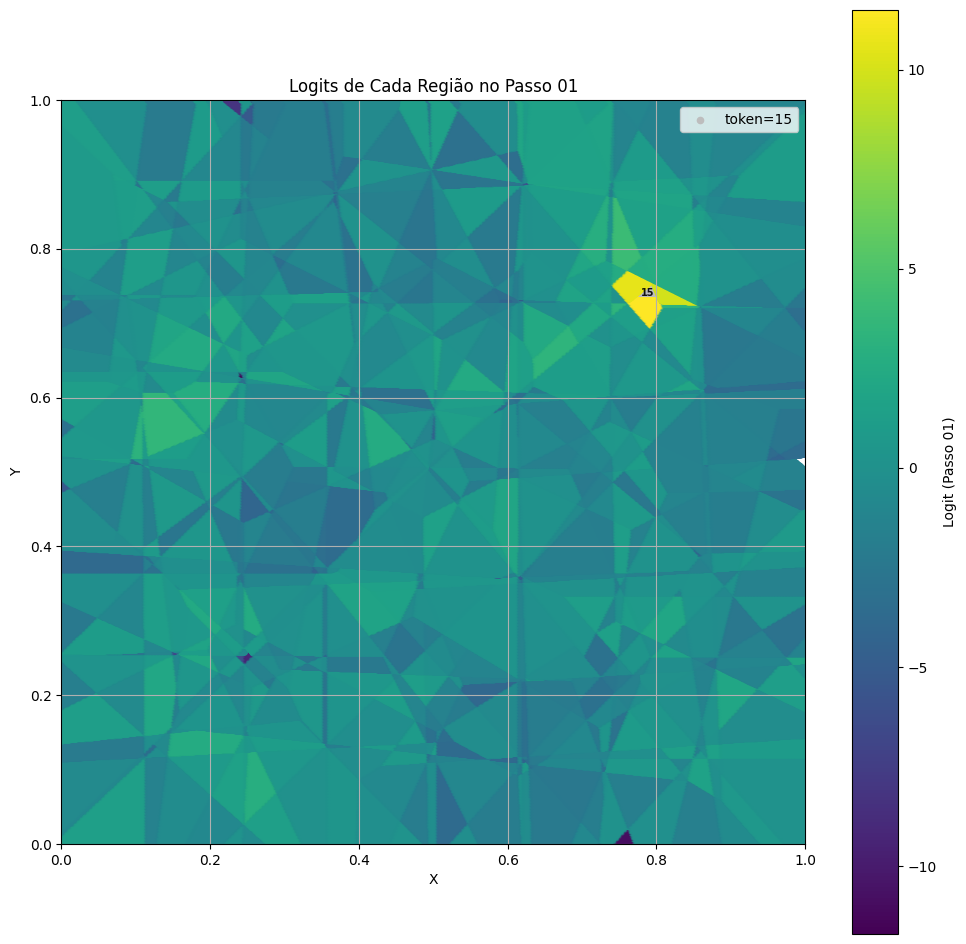

In [16]:
plot_logits_from_logits_df_w_pos(apd, distribs_logits, passo=0, token_atual=15)

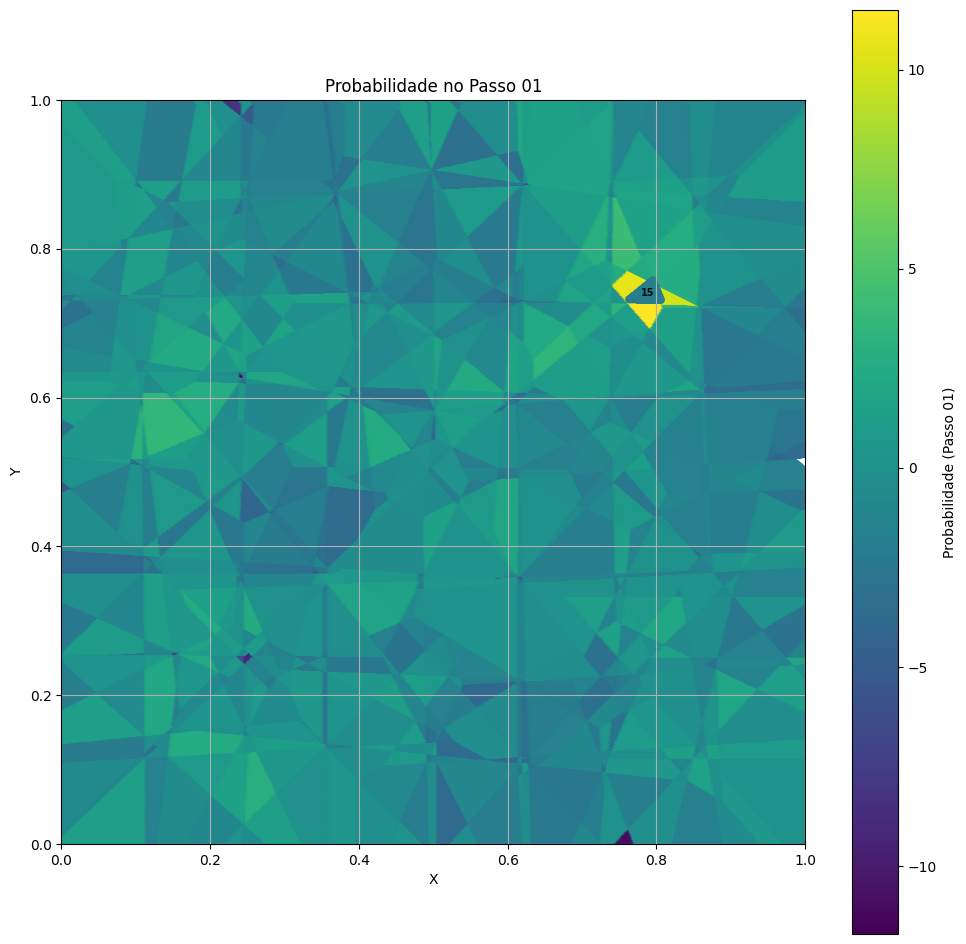

In [21]:
plot_prob_from_probs_df_w_pos(apd, distribs_logits, passo=0, token_atual=15, colorir_token_atual_por_prob=True)

In [25]:
# distribs_probs

# FIM